# Low-review classification — complete pipeline (compiled)

Single-notebook compilation of the four classification notebooks in `Phase 2/Classification/notebooks/`, in their run order, with the executed outputs of the full run (`QUICK = False`, seed 5006) carried over unchanged:

| Part | Source notebook | What it does |
|---|---|---|
| A | `data_preparation_audit.ipynb` | builds the feature table, cohort, stratified 54/13/33 split and the leakage audit |
| B | `baseline_variant_review.ipynb` | baselines, family ladder (logistic → tree → forest → CatBoost), stacking check, selection on validation, test scored once, importance, ablation |
| C | `ensemble_comparison.ipynb` | OOF ensembles (mean / convex / logistic stack), retention rule, class-balance study |
| D | `sampling_comparison.ipynb` | 4 models × 5 imbalance strategies inside the Pipeline, SHAP on the final forest |

Headings are prefixed with the part letter; code is otherwise verbatim. The shared setup block appears once below; each part keeps only its own extra imports and constants, so running this notebook top to bottom from the repository root, `Phase 2`, or `Phase 2/Classification` reproduces every table and figure in `outputs/` (about 1–2 h; Part B's search is the long step). Parts C and D read `outputs/selected_models.json`, written at the end of Part B, so they must run after it.

Verification: `python scripts/reproduce_classification.py --protocol-only` then `python scripts/verify_classification.py`.

## Shared setup

Path discovery, package imports and plotting defaults used by every part.

In [1]:
from pathlib import Path
import sys, warnings
_c = Path.cwd()
ROOT = next((p for parent in [_c, *_c.parents]
             for p in (parent, parent / "Classification", parent / "Phase 2" / "Classification")
             if (p / "config" / "problem_spec.json").is_file() and (p / "src" / "paths.py").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Run from the repository root, Phase 2, or Phase 2/Classification.")
sys.path.insert(0, str(ROOT / "src"))
import paths  # adds Phase 2/Regression/historical_temporal/src (regression package) to sys.path as well
warnings.filterwarnings("ignore")

import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import clf_config as config, clf_features as features, clf_split as split, clf_pipelines as pipelines, clf_evaluate as evaluate
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 40)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
ACCENT, GREY, RED = "#2563eb", "#9ca3af", "#dc2626"
for d in (config.FIGURES_DIR, config.RESULTS_DIR, config.PROCESSED_DIR, config.MODELS_DIR): d.mkdir(parents=True, exist_ok=True)
print("package root:", ROOT)

package root: c:\Users\wanglr\Downloads\scp5006\IT5006-clean\Phase 2\Classification


# Part A — Data preparation audit — feature table for the low-review problem

One row per order. All logic lives in `src/` (`clf_data`, `clf_features`); this notebook builds the table,
records the split, and runs the leakage audits. Geography (audited zip-prefix coordinates, maximum route
distance) and the seed are imported from the regression package in `Phase 2/Regression/historical_temporal/src`.

Split (`config.SPLIT_SCHEME = "stratified"`): the design of Zaghloul, Barakat & Rezk (2024, *J. Retailing and
Consumer Services* 79:103865), who model the same Olist target, with a validation set added — one stratified
67/33 train+validation / test split on `is_low_review`, then a stratified 80/20 train / validation split of
the 67% (seed 5006). The assignment is written to `data/split_manifest.csv`. Because the split is random in
time, every *outcome* that feeds a history feature (seller / route delivery and review history) is taken
from **training rows only**, so no validation or test label can reach a training feature; the audit below
checks that by recomputation.

What it does
1. joins the nine raw CSVs to one order-level table (`clf_data`)
2. derives targets, assigns the split, builds every feature group — including the five engineered features
   of Zaghloul et al. in prediction-point-safe form — and the point-in-time seller / route history (`clf_features`)
3. runs the leakage assertions and writes `data/orders_features.parquet`
4. prints the split summary (report Table 3) and draws report Figure 1

Raw CSVs are found via `OLIST_CSV_DIR`, then the repo's `data/`, `notebooks/data/` or `data/Olist_CSV/`, else `OLIST_ARCHIVE`.

*Compiled from `data_preparation_audit.ipynb`.*

## A1. Build

In [2]:
df = features.build_feature_table(save=True)
print(df.shape, "orders x columns ->", config.FEATURE_TABLE)
print("all orders by chronological window (reference only):", df.window.value_counts().to_dict())
print("split scheme:", config.SPLIT_SCHEME, "| manifest:", config.SPLIT_MANIFEST)
df.split.value_counts()

(99421, 78) orders x columns -> C:\Users\wanglr\Downloads\scp5006\IT5006-clean\Phase 2\Classification\data\orders_features.parquet
all orders by chronological window (reference only): {'train': 59427, 'maturation_gap': 19979, 'test': 12804, 'validation': 7211}
split scheme: stratified | manifest: C:\Users\wanglr\Downloads\scp5006\IT5006-clean\Phase 2\Classification\data\split_manifest.csv


split
train         52254
test          32172
validation    13064
excluded       1931
Name: count, dtype: int64

## A2. Cohort and split (report Table 3)

The cohort is every reviewed order with at least one line item, delivered or not, purchased 2016-09 to 2018-08.
Rows: **train** ≈ 54% · **validation** ≈ 13% · **test** ≈ 33%, all with the same positive rate by construction.
Roles, fixed before fitting: train — fit pipelines and 5-fold stratified CV for hyperparameters; validation —
baselines vs ladder comparison, CatBoost early stopping, F1 threshold, stacking retention rule; test — scored
once per final model.

The chronological windows of the regression package are kept in `purchase_month` / `window` for the drift
figure and the robustness check in `docs/current_progress.md`; they are not used for modelling here.

In [3]:
p2 = features.cohort(df, "p2")
print("P2 rows:", len(p2))
display(split.window_summary(p2, "p2"))
# stratified 5-fold CV on the training rows (used for every hyperparameter search and the OOF probabilities)
display(split.fold_summary(split.split_frame(p2)["train"], "p2"))
# the split is uniform over time: share of each split by purchase month
pd.crosstab(p2.purchase_month, p2.split, normalize="index").round(3).T

P2 rows: 97490


,orders,first purchase,last purchase,positives,positive rate,delivered by T share
window,,,,,,
train,52254,2016-09-04,2018-08-29,7394,0.1415,0.901
validation,13064,2016-10-03,2018-08-28,1849,0.1415,0.904
test,32172,2016-10-03,2018-08-29,4553,0.1415,0.901


,fit_rows,score_rows,fit_pos_rate,score_pos_rate
fold,,,,
1,41803,10451,0.1415,0.1415
2,41803,10451,0.1415,0.1415
3,41803,10451,0.1415,0.1415
4,41803,10451,0.1415,0.1415
5,41804,10450,0.1415,0.1414


purchase_month,2016-09,2016-10,2016-12,2017-01,2017-02,2017-03,2017-04,2017-05,2017-06,2017-07,2017-08,2017-09,2017-10,2017-11,2017-12,2018-01,2018-02,2018-03,2018-04,2018-05,2018-06,2018-07,2018-08
split,,,,,,,,,,,,,,,,,,,,,,,
test,0.0,0.365,0.0,0.339,0.342,0.329,0.337,0.332,0.333,0.324,0.321,0.334,0.338,0.330,0.327,0.326,0.324,0.327,0.328,0.330,0.330,0.330,0.340
train,1.0,0.512,1.0,0.537,0.523,0.540,0.529,0.535,0.538,0.536,0.538,0.529,0.528,0.542,0.542,0.539,0.543,0.533,0.535,0.537,0.536,0.535,0.531
validation,0.0,0.124,0.0,0.123,0.135,0.132,0.134,0.132,0.128,0.140,0.141,0.137,0.135,0.128,0.131,0.134,0.133,0.140,0.137,0.133,0.134,0.135,0.130


### Drift and right-censoring checks

The late-delivery rate and the review positive rate move month to month (Phase 1 Figure 2b): March 2018
is the worst month in the data (21% late, 23% low reviews) and July-August 2018 the calmest. A random split
mixes these months into every partition, so the metrics below estimate performance on the 2016-18 order mix,
not on a future month; the chronological robustness check in `docs/current_progress.md` quantifies that gap.
The last weeks of the extract are right-censored: an order only enters the delivered cohort if it arrived
before the extract date. Both facts go in report Section 2.3.

In [4]:
m = (df[df.seller_id.notna()].groupby("purchase_month")
       .agg(orders=("order_id", "size"),
            late_rate=("is_on_time", lambda s: 1 - s.mean()),
            low_review_rate=("is_low_review", "mean"),
            delivered_share=("order_delivered_customer_date", lambda s: s.notna().mean()),
            median_delivery_days=("delivery_days", "median")).round(3))
m["window"] = [features.assign_windows(pd.DataFrame({"purchase_month": [k]})).window[0] for k in m.index]
m

,orders,late_rate,low_review_rate,delivered_share,median_delivery_days,window
purchase_month,,,,,,
2016-09,3,1.000,1.000,0.333,54.813,train
2016-10,308,0.011,0.254,0.877,17.921,train
2016-12,1,0.000,0.000,1.000,4.693,train
2017-01,789,0.031,0.150,0.951,10.734,train
2017-02,1733,0.032,0.143,0.954,10.971,train
2017-03,2641,0.056,0.133,0.964,10.126,train
2017-04,2391,0.079,0.152,0.963,12.749,train
2017-05,3660,0.036,0.121,0.969,9.793,train
2017-06,3217,0.039,0.121,0.975,10.805,train


### Late delivery vs low review

Two levels. **Order level**: the phi coefficient (Pearson correlation of two binaries) and the two-way rate
table between `is_late` (delivered after the promised date, or not delivered) and `is_low_review`, on the
P2 cohort. **Month level**: Pearson and Spearman correlation between the monthly late rate and the monthly
low-review rate from the drift table above (months with fewer than 100 orders dropped), plus an order-weighted
Pearson so that the 308-order launch month (2016-10, 25% low reviews with almost no late deliveries) does not
dominate. The first is the individual effect that the delivery-status features exploit; the second is the drift
that a random split averages away.

order level: phi = 0.430  (chi-square p = 0.0e+00); low-review rate 59.5% when late vs 9.2% when on time -> relative risk 6.5x


is_low_review,review 3-5,review 1-2,orders
row_0,,,
on time,0.908,0.092,87891
late / not delivered,0.405,0.595,9599


month level (21 months): Pearson r = 0.475 (p = 0.029), Spearman rho = 0.313 (p = 0.166), order-weighted r = 0.850


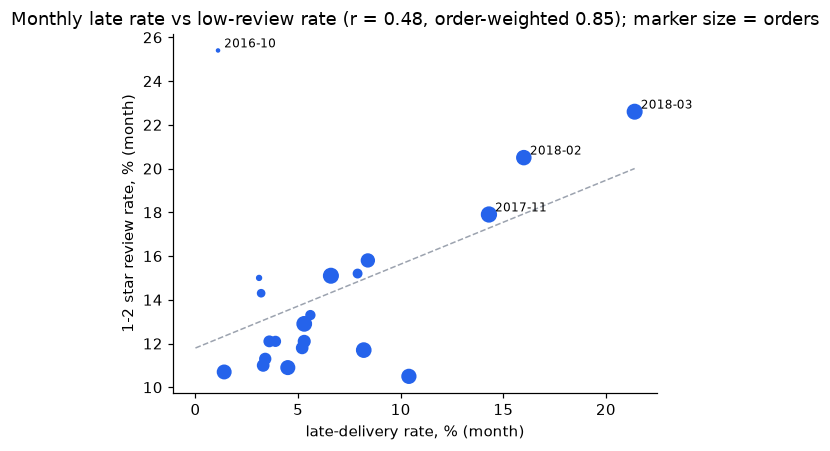

In [5]:
from scipy import stats
# order level: late = delivered after the promise, or not delivered at all
late = np.where(p2.order_delivered_customer_date.isna(), 1.0, 1 - p2.is_on_time.fillna(1.0))
low = p2.is_low_review.astype(float)
phi = np.corrcoef(late, low)[0, 1]
chi2, pval, _, _ = stats.chi2_contingency(pd.crosstab(late, low))
rate = pd.crosstab(late, low, normalize="index").rename(index={0.0: "on time", 1.0: "late / not delivered"},
                                                        columns={0.0: "review 3-5", 1.0: "review 1-2"}).round(3)
rate["orders"] = pd.Series(late).value_counts().rename({0.0: "on time", 1.0: "late / not delivered"})
print(f"order level: phi = {phi:.3f}  (chi-square p = {pval:.1e}); low-review rate {rate.iloc[1, 1]:.1%} when late vs {rate.iloc[0, 1]:.1%} when on time "
      f"-> relative risk {rate.iloc[1, 1] / rate.iloc[0, 1]:.1f}x")
display(rate)
# month level: drift table, months with >= 100 orders
mm = m[m.orders >= 100]
r_p, p_p = stats.pearsonr(mm.late_rate, mm.low_review_rate)
r_s, p_s = stats.spearmanr(mm.late_rate, mm.low_review_rate)
w = mm.orders / mm.orders.sum()   # order-weighted Pearson: 2016-10 (308 orders, launch month) otherwise dominates
cov = np.cov(mm.late_rate, mm.low_review_rate, aweights=w)
r_w = cov[0, 1] / np.sqrt(cov[0, 0] * cov[1, 1])
print(f"month level ({len(mm)} months): Pearson r = {r_p:.3f} (p = {p_p:.3f}), Spearman rho = {r_s:.3f} (p = {p_s:.3f}), order-weighted r = {r_w:.3f}")
corr = pd.DataFrame({"level": ["order (phi)", "month (Pearson)", "month (Spearman)", "month (order-weighted Pearson)"],
                     "correlation": [phi, r_p, r_s, r_w], "p_value": [pval, p_p, p_s, np.nan], "n": [len(p2), len(mm), len(mm), len(mm)]})
corr.to_csv(config.RESULTS_DIR / "late_vs_low_review_correlation.csv", index=False)
fig, ax = plt.subplots(figsize=(5.5, 4.2))
ax.scatter(mm.late_rate * 100, mm.low_review_rate * 100, color=ACCENT, s=mm.orders / 80)
for k, r in mm.iterrows():
    if r.late_rate > 0.12 or r.low_review_rate > 0.17: ax.annotate(k, (r.late_rate * 100, r.low_review_rate * 100), fontsize=8, xytext=(4, 2), textcoords="offset points")
b, a = np.polyfit(mm.late_rate * 100, mm.low_review_rate * 100, 1); xs = np.linspace(0, mm.late_rate.max() * 100, 10)
ax.plot(xs, a + b * xs, ls="--", color=GREY, lw=1)
ax.set_xlabel("late-delivery rate, % (month)"); ax.set_ylabel("1-2 star review rate, % (month)")
ax.set_title(f"Monthly late rate vs low-review rate (r = {r_p:.2f}, order-weighted {r_w:.2f}); marker size = orders")
plt.tight_layout(); fig.savefig(config.FIGURES_DIR / "01b_late_vs_low_review.png", bbox_inches="tight")

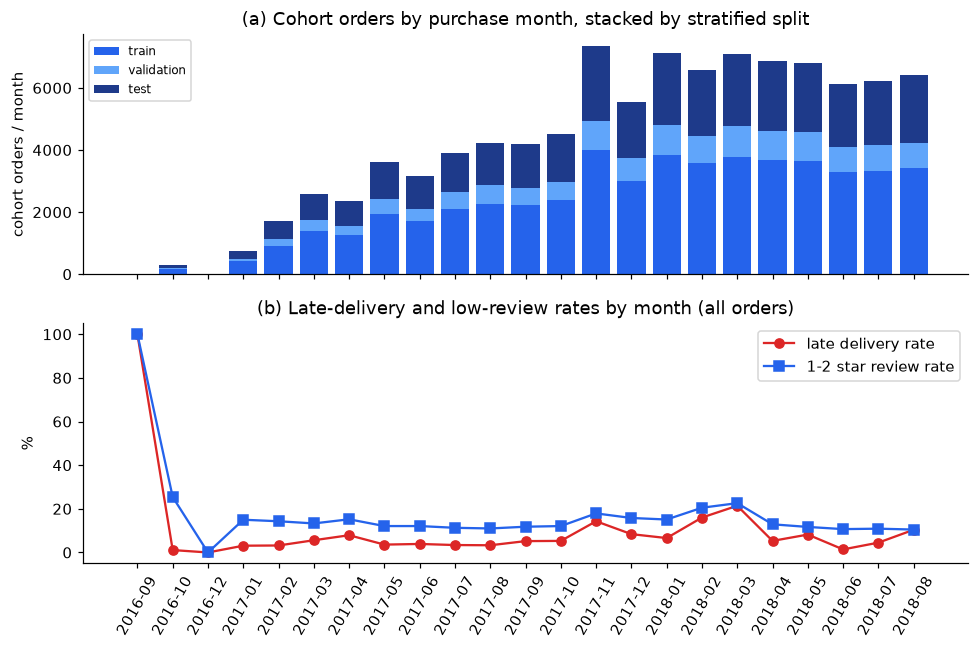

In [6]:
fig, ax = plt.subplots(2, 1, figsize=(9, 6), sharex=True)
by_split = pd.crosstab(p2.purchase_month, p2.split).reindex(m.index).fillna(0)[["train", "validation", "test"]]
x = np.arange(len(m))
colors = {"train": ACCENT, "validation": "#60a5fa", "test": "#1e3a8a"}
bottom = np.zeros(len(m))
for name in by_split.columns:
    ax[0].bar(x, by_split[name].values, bottom=bottom, color=colors[name], label=name); bottom += by_split[name].values
ax[0].set_ylabel("cohort orders / month"); ax[0].set_title("(a) Cohort orders by purchase month, stacked by stratified split"); ax[0].legend(fontsize=8)
ax[1].plot(x, m.late_rate * 100, marker="o", color=RED, label="late delivery rate")
ax[1].plot(x, m.low_review_rate * 100, marker="s", color=ACCENT, label="1-2 star review rate")
ax[1].set_ylabel("%"); ax[1].set_title("(b) Late-delivery and low-review rates by month (all orders)"); ax[1].legend()
ax[1].set_xticks(x); ax[1].set_xticklabels(m.index, rotation=60)
plt.tight_layout(); fig.savefig(config.FIGURES_DIR / "01_windows_and_rates.png", bbox_inches="tight")

## A3. Feature catalogue, prediction-point flags and missingness

Feature names follow Zaghloul et al. (2024) where they have one (`wd_actual_delivery_time`, `wd_delivery_time_delta`,
`total_order_value`, `payment_total`, `freight_ratio`). The difference from the paper is *when* a feature is evaluated:
every delivery-status feature is computed **as of the prediction point T** = min(delivered, estimated) — identical to the
paper's value for orders delivered by T, NaN (with an indicator) for the ~10% not yet delivered when the survey goes out.
The table flags these **T-dependent** features; they must never be used for a question asked at order time
(e.g. the regression problem), and `config/feature_roles.csv` carries the same flag.

Missing values are expected and meaningful for the T-dependent block. Every pipeline imputes with an indicator inside its own fit.

In [7]:
pp = config.prediction_point_table()
print("features by prediction point:"); display(pp.groupby("prediction_point").feature.agg(["size", lambda s: ", ".join(s)]).rename(columns={"size": "n", "<lambda_0>": "features"}))
print("T-dependent features (flagged):", config.features_at_T())
assert set(config.features_at_T()) == set(pp[pp.T_dependent].feature)
assert not set(config.features_at_T()) & set(config.features_for("p1")), "T-dependent features must not enter the order-time problem"

features by prediction point:


,n,features
prediction_point,,
order approval,34,"n_items, n_distinct_products, n_sellers, total..."
"purchase time (point-in-time, training-row outcomes only)",9,"seller_prior_orders, seller_tenure_days, selle..."
"survey trigger T = min(delivered, estimated) - T-dependent",9,"is_delivered, actual_delivery_time, delivery_t..."


T-dependent features (flagged): ['is_delivered', 'actual_delivery_time', 'delivery_time_delta', 'carrier_shipped', 'carrier_handover_days', 'carrier_transit_days', 'delivery_vs_seller_prior', 'wd_actual_delivery_time', 'wd_delivery_time_delta']


In [8]:
print(f"p2: {len(config.features_for('p2'))} features")
nan = p2[config.features_for("p2")].isna().mean().round(3)
nan[nan > 0].sort_values(ascending=False).to_frame("share missing (P2 cohort)")

p2: 52 features


,share missing (P2 cohort)
actual_delivery_time,0.098
wd_actual_delivery_time,0.098
delivery_time_delta,0.098
delivery_vs_seller_prior,0.098
carrier_transit_days,0.098
wd_delivery_time_delta,0.098
carrier_handover_days,0.015
main_category,0.014
max_distance_km,0.005


In [9]:
# the T-dependent delivery block is where the Problem 2 signal lives
p2.groupby("is_delivered").is_low_review.agg(["mean", "size"]).rename(columns={"mean": "low-review rate", "size": "orders"})

,low-review rate,orders
is_delivered,,
0.0,0.594749,9599
1.0,0.092012,87891


## A4. Leakage audit

`features.assert_no_leakage` is structural (no post-outcome column can be a feature; the delivery-as-of-T block is
empty for orders not delivered by T). `features.leakage_audit` adds empirical checks: seller history recomputed
from scratch for a sample of orders — only outcomes known before purchase **and belonging to training rows** may
contribute, and the smoothed seller late rate is rebuilt from those rows and compared exactly — internal consistency
of the delivery-as-of-T block, the share of reviews *answered* before the survey trigger T (must be zero: those orders are
excluded from the cohort because their label existed at the prediction point), and the ranking power of every
feature on its own (a value near 1.0 would mean a feature encodes the label; `is_delivered` leading at about 0.77
is the delivery effect Phase 1 documented, not leakage).

In [10]:
features.assert_no_leakage(p2, "p2")
print("post-outcome columns (never features):", sorted(config.POST_OUTCOME_COLUMNS))
audit = features.leakage_audit(p2, "p2", sample=3000, full=df)
for k in ("history", "at_T", "review_time"):
    print(f"--- {k}"); print(audit[k].round(4).to_string())
audit["single_feature_auc"].to_csv(config.RESULTS_DIR / "single_feature_auc.csv", index=False)
display(audit["single_feature_auc"].head(12).round(3))
assert audit["history"]["only outcomes known before purchase"] == 1.0
assert audit["history"]["late rate rebuilt from training-row outcomes only"] == 1.0
assert audit["history"]["low-review rate rebuilt from reviews answered before purchase"] == 1.0
assert audit["review_time"]["reviews answered before T (must be 0: excluded from cohort)"] == 0.0
assert audit["single_feature_auc"].roc_auc.max() < 0.9, "a single feature ranks the label almost perfectly: inspect it"
split.window_summary(p2, "p2").to_csv(config.RESULTS_DIR / "split_summary.csv")
split.fold_summary(split.split_frame(p2)["train"], "p2").to_csv(config.RESULTS_DIR / "fold_summary.csv")
import json
json.dump({"orders": int(len(df)), "p2_cohort": int(len(p2)), "windows": split.window_summary(p2, "p2").orders.to_dict(),
           "split_scheme": config.SPLIT_SCHEME, "test_size": config.TEST_SIZE, "validation_size": config.VALIDATION_SIZE,
           "features": len(config.features_for("p2")), "leakage_audit_passed": True,
           "reviews_answered_before_T_share": float(audit["review_time"]["reviews answered before T (must be 0: excluded from cohort)"]),
           "surveys_sent_before_T_share": float(audit["review_time"]["surveys sent before T (creation date; informational)"])},
          open(config.ROOT / "outputs" / "data_quality.json", "w"), indent=2)
print("OK - leakage audit passed")

post-outcome columns (never features): ['delivery_days', 'has_review_comment', 'is_low_review', 'is_on_time', 'order_delivered_carrier_date', 'order_delivered_customer_date', 'order_status', 'review_answer_timestamp', 'review_creation_date', 'review_score', 'survey_trigger_time']
--- history
orders checked                                                   3000.0
seller_prior_orders exact match                                     1.0
only outcomes known before purchase                                 1.0
late rate rebuilt from training-row outcomes only                   1.0
low-review rate rebuilt from reviews answered before purchase       1.0
--- at_T
actual_delivery_time is NaN when not delivered by T    1.0000
delivery_time_delta <= 0 when delivered by T           1.0000
carrier_handover only when carrier date <= T           1.0000
is_delivered share                                     0.9015
--- review_time
reviews answered before T (must be 0: excluded from cohort)    0.0000
surv

,feature,roc_auc,pr_auc
0,is_delivered,0.680,0.326
1,seller_id_enc,0.609,0.205
2,customer_zip2,0.601,0.195
3,total_freight,0.578,0.190
4,main_category,0.569,0.171
5,customer_state,0.563,0.172
6,carrier_handover_days,0.562,0.177
7,wd_actual_delivery_time,0.557,0.168
8,n_items,0.556,0.169
9,seller_prior_low_review_rate,0.554,0.170


OK - leakage audit passed


# Part B — Baseline and variant review — low-review risk classification

Target `is_low_review` (review score 1-2) at the survey trigger T = min(delivered date, estimated date).
Stakeholder: Olist CX / seller-quality team. Primary metric: **PR-AUC** (fixed before modelling).

Protocol
* stratified split after Zaghloul et al. (2024) with a validation set: 67/33 train+validation / test, then 80/20 train / validation, all stratified on the label (seed 5006; `data/split_manifest.csv`)
* family ladder A (logistic) → B (decision tree → random forest → CatBoost) → C (stacking)
* class weights, not resampling; threshold chosen on validation to maximise F1, then frozen
* RandomizedSearchCV on the training rows with 5 stratified shuffled folds (`split.cv_folds`); every pipeline's
  first step recomputes the seller / route history from the fold's fit rows only (`features.HistoryInPipeline`)
* **selection uses validation only**; the test set is scored once, at the end, for every row of the table, and
  no decision in this package is taken on a test number

Set `QUICK = True` for a dry run (4 search draws, small forests, full training window); the report numbers come from `QUICK = False`.

*Compiled from `baseline_variant_review.ipynb`.*

### Part B setup

In [ ]:
import joblib, json, time
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import precision_recall_curve
from sklearn.calibration import calibration_curve

QUICK = False
N_ITER = 4 if QUICK else 30
PROBLEM = "p2"
SCORING = evaluate.SCORING[PROBLEM]       # average_precision


## B1. Data

In [11]:
df = features.load_feature_table()
cohort = features.cohort(df, PROBLEM)
S = split.split_frame(cohort)
X_tr, y_tr = split.xy(S["train"], PROBLEM)
X_va, y_va = split.xy(S["validation"], PROBLEM)
X_te, y_te = split.xy(S["test"], PROBLEM)
CV = split.cv_folds(S["train"], PROBLEM)     # 5 stratified shuffled folds (config.SPLIT_SCHEME)
N_FEATURES = len(config.features_for(PROBLEM))
print({k: v.shape for k, v in S.items()}, f"| features: {N_FEATURES} (+{X_tr.shape[1] - N_FEATURES} history-context columns consumed by the first pipeline step) | split:", config.SPLIT_SCHEME)
display(split.window_summary(cohort, PROBLEM))
split.fold_summary(S["train"], PROBLEM)

{'train': (52254, 78), 'validation': (13064, 78), 'test': (32172, 78)} | features: 52 (+9 history-context columns consumed by the first pipeline step) | split: stratified


,orders,first purchase,last purchase,positives,positive rate,delivered by T share
window,,,,,,
train,52254,2016-09-04,2018-08-29,7394,0.1415,0.901
validation,13064,2016-10-03,2018-08-28,1849,0.1415,0.904
test,32172,2016-10-03,2018-08-29,4553,0.1415,0.901


,fit_rows,score_rows,fit_pos_rate,score_pos_rate
fold,,,,
1,41803,10451,0.1415,0.1415
2,41803,10451,0.1415,0.1415
3,41803,10451,0.1415,0.1415
4,41803,10451,0.1415,0.1415
5,41804,10450,0.1415,0.1414


## B2. Baselines on the same rows

* majority class: predict nobody complains → PR-AUC equals the positive rate
* one-feature rule: "not delivered by the promised date ⇒ low review" (the strongest single Phase 1 finding)

In [12]:
results = evaluate.ResultsTable(PROBLEM)
thresholds, val_proba, test_proba, fitted = {}, {}, {}, {}

def record(name, p_tr, p_va, p_te, thr, extra=None):
    """One row: train / validation / test metrics at the frozen threshold."""
    row = {}
    for tag, y, p in (("train", y_tr, p_tr), ("val", y_va, p_va), ("test", y_te, p_te)):
        if p is None: continue
        m = evaluate.classification_metrics(y, p, thr)
        row.update({f"{tag}_{k}": v for k, v in m.items() if k != "threshold"})
    row["threshold"] = thr
    row.update(extra or {})
    results.add(name, **row)
    thresholds[name], val_proba[name], test_proba[name] = thr, p_va, p_te

# majority class: constant score
const = lambda y: np.full(len(y), y_tr.mean())
record("baseline_majority", const(y_tr), const(y_va), const(y_te), thr=1.0)
# rule: late at T (not delivered by the promised date) -> positive
rule = lambda X: (1 - X.is_delivered.values).astype(float)
record("baseline_rule_late", rule(X_tr), rule(X_va), rule(X_te), thr=0.5)
results.frame()[["val_pr_auc", "val_precision", "val_recall", "val_f1"]]

,val_pr_auc,val_precision,val_recall,val_f1
model,,,,
baseline_majority,0.141534,0.000000,0.000000,0.00000
baseline_rule_late,0.325568,0.595238,0.405625,0.48247


## B3. Family ladder with tuning

Each family starts from its simplest variant. Searches are scored on average precision over five stratified
shuffled folds of the training rows. The threshold for each model is the F1-maximising point on **validation**,
frozen before the test set is touched.

In [13]:
models = pipelines.classification_models(PROBLEM)
if QUICK:  # small budgets for a dry run; report numbers come from QUICK = False
    models["B_rf"][1]["model__n_estimators"] = [100]
    models["B_catboost"][1]["model__iterations"] = [100, 200]
searches, best_params = {}, {}

for name, (pipe, space) in models.items():
    t0 = time.time()
    if space is None:
        est = pipe.fit(X_tr, y_tr); cv = {}
    else:
        rs = RandomizedSearchCV(pipe, space, n_iter=N_ITER,   # a 7-point list grid is exhausted, not sampled
                                cv=CV, scoring=SCORING, n_jobs=1,
                                random_state=config.RANDOM_STATE, refit=True)
        rs.fit(X_tr, y_tr); est = rs.best_estimator_; searches[name] = rs
        cv = evaluate.cv_summary(rs); best_params[name] = {k: (float(v) if isinstance(v, (np.floating, float)) else v) for k, v in rs.best_params_.items()}
    fitted[name] = est
    features.assert_history_context_dropped(est, X_tr)   # no key / timestamp / outcome column reaches the preprocessor
    p_tr, p_va, p_te = (est.predict_proba(X)[:, 1] for X in (X_tr, X_va, X_te))
    thr = evaluate.best_threshold(y_va, p_va)
    record(name, p_tr, p_va, p_te, thr, extra=cv)
    print(f"{name:15s} val PR-AUC {evaluate.classification_metrics(y_va, p_va)['pr_auc']:.3f}  "
          f"cv {cv.get('cv_mean', float('nan')):.3f}±{cv.get('cv_sd', float('nan')):.3f}  thr {thr:.2f}  {time.time()-t0:.0f}s")

A_linear_base   val PR-AUC 0.468  cv nan±nan  thr 0.68  5s
A_linear_tuned  val PR-AUC 0.469  cv 0.499±0.013  thr 0.68  114s
B_tree_base     val PR-AUC 0.469  cv 0.490±0.008  thr 0.60  522s
B_rf            val PR-AUC 0.491  cv 0.515±0.010  thr 0.59  6994s
B_catboost      val PR-AUC 0.483  cv 0.507±0.010  thr 0.63  11488s


### CatBoost: iterations by early stopping on validation

The search treats `iterations` as a coarse hyperparameter; the final CatBoost refits the best configuration
with `od_wait = 50` on the validation window and replaces the searched model if validation PR-AUC improves.

In [14]:
cb_es = pipelines.fit_catboost_early_stopping(fitted["B_catboost"], X_tr, y_tr, X_va, y_va,
                                              max_iterations=400 if QUICK else 3000)
p_va_es = cb_es.predict_proba(X_va)[:, 1]
ap_es, ap_rs = (evaluate.classification_metrics(y_va, p)["pr_auc"] for p in (p_va_es, val_proba["B_catboost"]))
print(f"early-stopped iterations: {cb_es.best_iteration_}  val PR-AUC {ap_es:.4f} vs searched {ap_rs:.4f}")
if ap_es > ap_rs:
    fitted["B_catboost"] = cb_es
    p_tr, p_te = cb_es.predict_proba(X_tr)[:, 1], cb_es.predict_proba(X_te)[:, 1]
    results.rows = [r for r in results.rows if r["model"] != "B_catboost"]
    record("B_catboost", p_tr, p_va_es, p_te, evaluate.best_threshold(y_va, p_va_es),
           extra={**evaluate.cv_summary(searches["B_catboost"]), "best_iteration": cb_es.best_iteration_})

early-stopped iterations: 467  val PR-AUC 0.4829 vs searched 0.4834


## B4. Model selection on validation, then stacking

The best single model is the one with the highest validation PR-AUC. Stacking (Family C) is fitted on the
tuned A_linear, B_rf and B_catboost pipelines and is **retained only if** it beats the best single model
by at least 1% relative on validation PR-AUC. Ties within one CV standard deviation go to the simpler model.

In [15]:
tbl = results.frame()
ladder = [m for m in models]
best_single = tbl.loc[ladder, "val_pr_auc"].idxmax()
print("best single model on validation:", best_single, round(tbl.loc[best_single, "val_pr_auc"], 4))

t0 = time.time()
stack = pipelines.make_stacking(PROBLEM, fitted)
if QUICK: stack.set_params(B_rf__model__n_estimators=60, B_catboost__model__iterations=150)
stack.fit(X_tr, y_tr)
p_tr, p_va, p_te = (stack.predict_proba(X)[:, 1] for X in (X_tr, X_va, X_te))
record("C_stacking", p_tr, p_va, p_te, evaluate.best_threshold(y_va, p_va),
       extra={"meta_coef": json.dumps(dict(zip(["A_linear_tuned", "B_rf", "B_catboost"], np.round(stack.final_estimator_.coef_[0], 3).tolist())))})
fitted["C_stacking"] = stack
gain = tbl.loc[best_single, "val_pr_auc"]
ap_stack = evaluate.classification_metrics(y_va, p_va)["pr_auc"]
keep_stack = ap_stack >= 1.01 * gain
FINAL = "C_stacking" if keep_stack else best_single
print(f"stacking val PR-AUC {ap_stack:.4f} vs {gain:.4f} -> {'retained' if keep_stack else 'not retained'}; FINAL = {FINAL}  ({time.time()-t0:.0f}s)")

best single model on validation: B_rf 0.4913
stacking val PR-AUC 0.4892 vs 0.4913 -> not retained; FINAL = B_rf  (816s)


## B5. Results table (report Table 7)

Every model is scored on the test set once, at its frozen threshold. `cv_mean ± cv_sd` is the 5-fold stratified
cross-validation estimate of PR-AUC for the chosen configuration on the training rows.

In [16]:
cols = ["cv_mean", "cv_sd", "val_pr_auc", "test_pr_auc", "test_roc_auc", "test_precision", "test_recall",
        "test_f1", "test_balanced_acc", "test_brier", "test_recall_top10", "test_accuracy", "threshold"]
table7 = results.save("model_comparison")[cols].round(3)
table7

,cv_mean,cv_sd,val_pr_auc,test_pr_auc,test_roc_auc,test_precision,test_recall,test_f1,test_balanced_acc,test_brier,test_recall_top10,test_accuracy,threshold
model,,,,,,,,,,,,,
baseline_majority,NaN,NaN,0.142,0.142,0.500,0.000,0.000,0.000,0.500,0.121,0.101,0.858,1.000
baseline_rule_late,NaN,NaN,0.326,0.326,0.682,0.589,0.412,0.485,0.682,0.124,0.413,0.876,0.500
A_linear_base,NaN,NaN,0.468,0.490,0.786,0.541,0.498,0.519,0.714,0.166,0.426,0.869,0.676
A_linear_tuned,0.499,0.013,0.469,0.490,0.786,0.545,0.494,0.518,0.713,0.166,0.430,0.870,0.684
B_tree_base,0.490,0.008,0.469,0.484,0.771,0.468,0.549,0.505,0.723,0.167,0.423,0.848,0.604
B_rf,0.515,0.010,0.491,0.505,0.788,0.508,0.523,0.515,0.720,0.145,0.428,0.861,0.590
B_catboost,0.507,0.010,0.483,0.500,0.789,0.530,0.510,0.519,0.718,0.159,0.427,0.867,0.634
C_stacking,NaN,NaN,0.489,0.508,0.790,0.552,0.492,0.520,0.713,0.093,0.427,0.872,0.309


In [17]:
# train vs validation gap = overfitting check
results.frame()[["train_pr_auc", "val_pr_auc", "test_pr_auc"]].round(3)

,train_pr_auc,val_pr_auc,test_pr_auc
model,,,
baseline_majority,0.142,0.142,0.142
baseline_rule_late,0.332,0.326,0.326
A_linear_base,0.509,0.468,0.490
A_linear_tuned,0.507,0.469,0.490
B_tree_base,0.524,0.469,0.484
B_rf,0.602,0.491,0.505
B_catboost,0.554,0.483,0.500
C_stacking,0.581,0.489,0.508


## B6. Figures (report Figure 3)

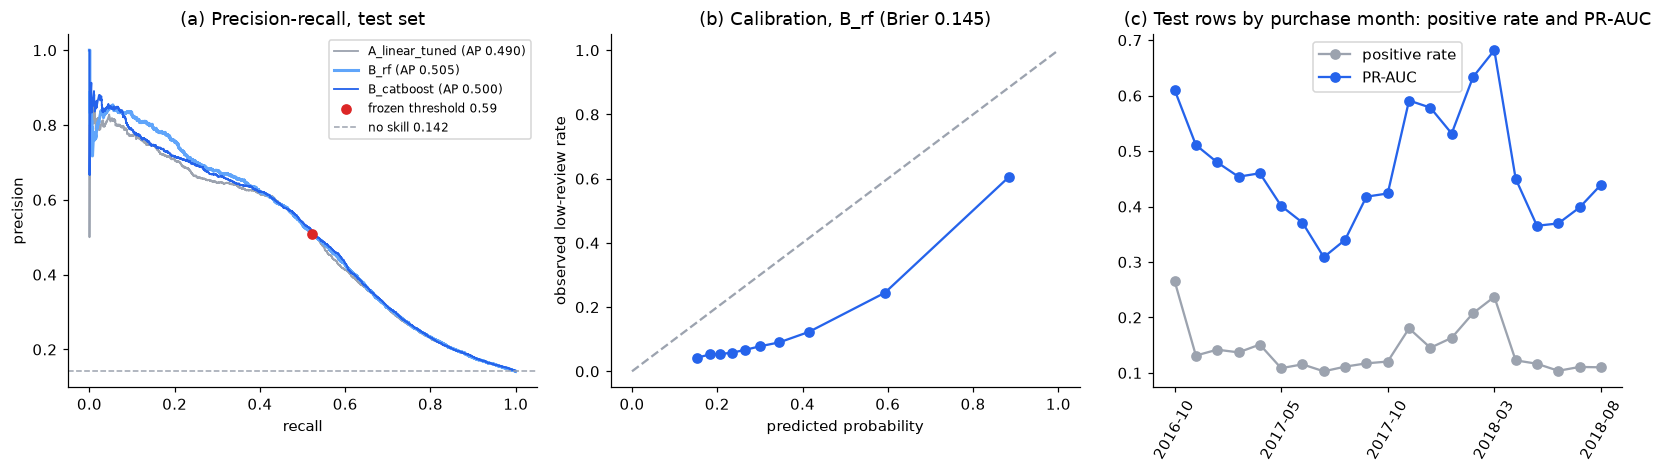

In [18]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4.4))
# (a) PR curves on test for the family-best models
show = ["A_linear_tuned", "B_rf", "B_catboost"] + (["C_stacking"] if keep_stack else [])
palette = dict(zip(show, [GREY, "#60a5fa", ACCENT, "#1e3a8a"]))
for name in show:
    p, r, _ = precision_recall_curve(y_te, test_proba[name])
    ap = evaluate.classification_metrics(y_te, test_proba[name])["pr_auc"]
    ax[0].plot(r, p, color=palette[name], label=f"{name} (AP {ap:.3f})", lw=2 if name == FINAL else 1.2)
m = evaluate.classification_metrics(y_te, test_proba[FINAL], thresholds[FINAL])
ax[0].scatter([m["recall"]], [m["precision"]], color=RED, zorder=5, label=f"frozen threshold {thresholds[FINAL]:.2f}")
ax[0].axhline(y_te.mean(), ls="--", color=GREY, lw=1, label=f"no skill {y_te.mean():.3f}")
ax[0].set_xlabel("recall"); ax[0].set_ylabel("precision"); ax[0].set_title("(a) Precision-recall, test set"); ax[0].legend(fontsize=8)
# (b) calibration of the final model
frac, mean_pred = calibration_curve(y_te, test_proba[FINAL], n_bins=10, strategy="quantile")
ax[1].plot(mean_pred, frac, marker="o", color=ACCENT); ax[1].plot([0, 1], [0, 1], ls="--", color=GREY)
ax[1].set_xlabel("predicted probability"); ax[1].set_ylabel("observed low-review rate"); ax[1].set_title(f"(b) Calibration, {FINAL} (Brier {m['brier']:.3f})")
# (c) drift: test rows by purchase month (the split is uniform over time, so every month is represented)
te = S["test"].assign(proba=test_proba[FINAL])
drift = te.groupby("purchase_month").apply(lambda g: pd.Series({"positive rate": g.is_low_review.mean(),
        "PR-AUC": evaluate.classification_metrics(g.is_low_review, g.proba)["pr_auc"]}))
drift.plot(ax=ax[2], marker="o", color=[GREY, ACCENT]); ax[2].set_title("(c) Test rows by purchase month: positive rate and PR-AUC"); ax[2].set_xlabel(""); ax[2].tick_params(axis="x", rotation=60)
plt.tight_layout(); fig.savefig(config.FIGURES_DIR / "02_pr_calibration_drift.png", bbox_inches="tight")

## B7. Interpretability (report Figure 4b, Section 6.4)

Permutation importance on the **validation** set, model-agnostic so families are comparable, plus the
logistic coefficients as a linear cross-check. Zaghloul et al. (2024) rank `wd_delivery_time_delta` first and
`wd_actual_delivery_time` third on the same data; their counterparts here are `wd_delivery_time_delta` and
`wd_actual_delivery_time`.

,feature,importance_mean,importance_sd
0,n_items,0.029755,0.001799
1,is_delivered,0.017987,0.005830
2,wd_delivery_time_delta,0.012349,0.005843
3,carrier_transit_days,0.012279,0.005680
4,delivery_vs_seller_prior,0.010285,0.005817
5,delivery_time_delta,0.009465,0.005503
6,actual_delivery_time,0.008679,0.005579
7,wd_actual_delivery_time,0.008567,0.005332
8,seller_id_enc,0.006910,0.000977
9,promised_days,0.006363,0.001879


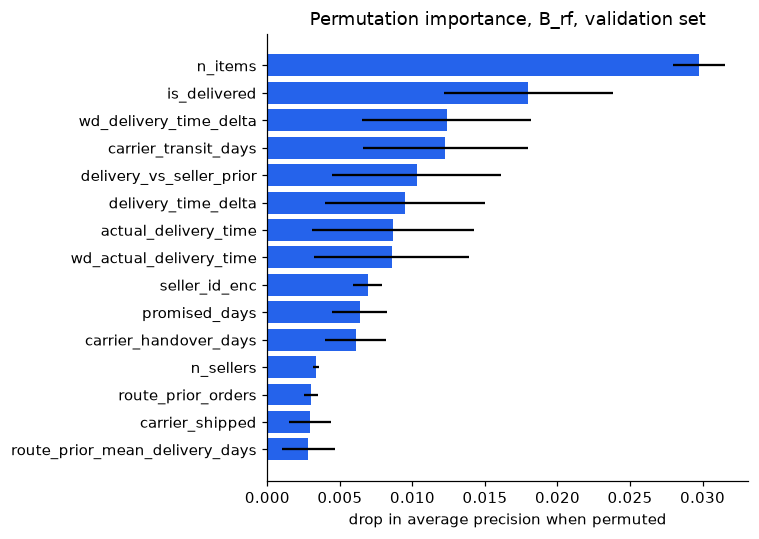

In [19]:
imp_model = best_single  # permutation importance on the best single model (a stacker's importances are not attributable)
# permute the 52 features after the (fitted) history step, so key / timestamp columns are never permuted
H_va = fitted[imp_model].named_steps["history"].transform(X_va)
imp = evaluate.permutation_table(fitted[imp_model][1:], H_va, y_va, SCORING, n_repeats=3 if QUICK else 5, top=15)
imp.to_csv(config.RESULTS_DIR / "permutation_importance.csv", index=False)
fig, ax = plt.subplots(figsize=(7, 5))
ax.barh(imp.feature[::-1], imp.importance_mean[::-1], xerr=imp.importance_sd[::-1], color=ACCENT)
ax.set_xlabel("drop in average precision when permuted"); ax.set_title(f"Permutation importance, {imp_model}, validation set")
plt.tight_layout(); fig.savefig(config.FIGURES_DIR / "03_permutation_importance.png", bbox_inches="tight")
imp

In [20]:
# linear cross-check: standardised logistic coefficients
lin = fitted["A_linear_tuned"]
names = lin.named_steps["pre"].get_feature_names_out()
coef = pd.Series(lin.named_steps["model"].coef_[0], index=names).sort_values()
pd.concat([coef.head(8), coef.tail(8)]).round(3).to_frame("logistic coefficient (standardised)")

,logistic coefficient (standardised)
low__seller_state_MT,-0.548
skew__max_weight_g,-0.499
low__seller_state_MS,-0.349
low__customer_region_North,-0.328
low__customer_state_RN,-0.256
low__customer_state_RR,-0.250
low__customer_state_AP,-0.246
num__carrier_transit_days,-0.228
low__main_payment_type_voucher,0.274
high__customer_zip2,0.303


## B8. Ablation: how much does the delivery block add?

Refits the best single configuration without the `delivery` group — the nine **T-dependent** features flagged in
`config/feature_roles.csv` (`config.features_at_T()`). The PR-AUC drop quantifies the Phase 1 finding that delivery
performance drives satisfaction, and is the number to quote in Section 6.2.

In [21]:
from sklearn.base import clone
delivery = config.FEATURE_GROUPS["delivery"]            # the 9 T-dependent features (config.features_at_T())
keep = [c for c in X_tr.columns if c not in delivery]   # history-context columns stay: the first step consumes them
abl = clone(fitted[best_single])
pre = abl.named_steps["pre"]
# drop the delivery block from every transformer's column list
pre.set_params(transformers=[(n, t, [c for c in cols if c not in delivery]) for n, t, cols in pre.transformers])
if best_single == "B_catboost":
    abl.set_params(model__cat_features=[c for c in abl.named_steps["model"].cat_features if c in keep])
abl.fit(X_tr[keep], y_tr)
# the history step derives delivery_vs_seller_prior from actual_delivery_time, so it is absent too
assert not set(abl.named_steps["history"].transform(X_va[keep].head()).columns) & set(delivery)
ap_full = evaluate.classification_metrics(y_va, val_proba[best_single])["pr_auc"]
ap_abl = evaluate.classification_metrics(y_va, abl.predict_proba(X_va[keep])[:, 1])["pr_auc"]
print(f"{best_single}: validation PR-AUC with the delivery block {ap_full:.3f} -> without {ap_abl:.3f}  "
      f"({len(delivery)} T-dependent features removed: {', '.join(delivery)})")

B_rf: validation PR-AUC with the delivery block 0.491 -> without 0.297  (9 T-dependent features removed: is_delivered, actual_delivery_time, delivery_time_delta, carrier_shipped, carrier_handover_days, carrier_transit_days, delivery_vs_seller_prior, wd_actual_delivery_time, wd_delivery_time_delta)


## B9. Optional sensitivity: class weights vs SMOTE (Appendix Table A3)

Runs only if `imbalanced-learn` is installed. Two rows: logistic regression and random forest with SMOTE inside the
pipeline (so it is applied per fold, to training rows only), compared with their class-weighted versions above.

In [22]:
try:
    from imblearn.over_sampling import SMOTE
    from imblearn.pipeline import Pipeline as ImbPipeline
    from sklearn.linear_model import LogisticRegression
    from sklearn.ensemble import RandomForestClassifier
    rows = []
    for name, model in [("A_logistic_smote", LogisticRegression(max_iter=2000, random_state=config.RANDOM_STATE)),
                        ("B_rf_smote", RandomForestClassifier(n_estimators=100 if QUICK else 400, min_samples_leaf=20,
                                                               n_jobs=-1, random_state=config.RANDOM_STATE))]:
        kind = "linear" if name.startswith("A") else "tree"
        pipe = ImbPipeline([pipelines.history_step(), ("pre", pipelines.make_preprocessor(kind, PROBLEM)),
                            ("smote", SMOTE(random_state=config.RANDOM_STATE)), ("model", model)]).fit(X_tr, y_tr)
        p_va, p_te = pipe.predict_proba(X_va)[:, 1], pipe.predict_proba(X_te)[:, 1]
        thr = evaluate.best_threshold(y_va, p_va)
        rows.append({"model": name, **{f"val_{k}": v for k, v in evaluate.classification_metrics(y_va, p_va, thr).items()},
                     **{f"test_{k}": v for k, v in evaluate.classification_metrics(y_te, p_te, thr).items()}})
    a3 = pd.DataFrame(rows).set_index("model"); a3.to_csv(config.RESULTS_DIR / "smote_sensitivity.csv")
    display(a3[["val_pr_auc", "test_pr_auc", "test_precision", "test_recall", "test_f1", "test_brier"]].round(3))
except ImportError:
    print("imbalanced-learn not installed - skip (pip install imbalanced-learn to run Appendix Table A3)")

,val_pr_auc,test_pr_auc,test_precision,test_recall,test_f1,test_brier
model,,,,,,
A_logistic_smote,0.464,0.488,0.503,0.529,0.516,0.166
B_rf_smote,0.478,0.500,0.566,0.469,0.513,0.100


## B10. Save for the report and Phase 3

* `outputs/tables/model_comparison.csv` – report Table 7
* `outputs/selected_models.json` – chosen configurations (Appendix Table A1), final model, frozen thresholds
* `models/final_pipeline.joblib` – the final pipeline for the Phase 3 app, with its frozen threshold

In [23]:
config.MODELS_DIR.mkdir(parents=True, exist_ok=True)
with open(config.ROOT / "outputs" / "selected_models.json", "w") as f:
    json.dump({"best_params": best_params, "final_model": FINAL, "thresholds": thresholds, "seed": config.RANDOM_STATE,
               "stacking_retained": bool(keep_stack), "quick_mode": QUICK, "test_scored": True,
               "features": list(X_tr.columns)}, f, indent=2, default=str)
joblib.dump({"pipeline": fitted[FINAL], "threshold": thresholds[FINAL], "features": list(X_tr.columns),
             "problem": PROBLEM, "model_name": FINAL}, config.MODELS_DIR / "final_pipeline.joblib")
# per-order predictions for independent verification (git-ignored, regenerated by this notebook)
(config.ROOT / "outputs" / "predictions").mkdir(parents=True, exist_ok=True)
for tag, frame, probas in (("validation", S["validation"], val_proba), ("test", S["test"], test_proba)):
    pd.DataFrame({"order_id": frame.order_id, "is_low_review": frame.is_low_review.astype(int), **probas}).to_csv(
        config.ROOT / "outputs" / "predictions" / f"{tag}_predictions.csv", index=False, float_format="%.10g")
print("final model:", FINAL, "| threshold:", round(thresholds[FINAL], 3))
table7.loc[[FINAL]]

final model: B_rf | threshold: 0.59


,cv_mean,cv_sd,val_pr_auc,test_pr_auc,test_roc_auc,test_precision,test_recall,test_f1,test_balanced_acc,test_brier,test_recall_top10,test_accuracy,threshold
model,,,,,,,,,,,,,
B_rf,0.515,0.01,0.491,0.505,0.788,0.508,0.523,0.515,0.72,0.145,0.428,0.861,0.59


# Part C — Ensemble comparison — low-review classification (Family C)

Mirror of the regression package's `ensemble_comparison.ipynb`. Base models are the tuned Family A
logistic regression and the two Family B models (random forest, CatBoost) from `baseline_variant_review`.
Four combinations are compared on the **validation set** and the chosen one is scored **once** on test:

| Method | What is learned |
|---|---|
| `mean_three` | arithmetic mean of the three probabilities — nothing |
| `mean_rf_cb` | mean of the two tree models — nothing |
| `convex` | non-negative weights summing to one, maximising OOF average precision (simplex grid, step 0.05) |
| `logit_stack` | logistic regression on logit(p) of the three, fitted on OOF rows |

OOF probabilities come from the same five stratified shuffled folds as the searches (`split.cv_folds`), so the
meta-learner only ever sees predictions made by a base model that had not seen that order; every training row
gets exactly one OOF probability.

The notebook also carries the two audits the report needs: an empirical **leakage audit** of the feature table
and a **class-balance study** (weighting vs. none vs. resampling vs. calibration). Set `QUICK = True` for a
dry run; the report numbers come from `QUICK = False` after `30` has been run in full.

*Compiled from `ensemble_comparison.ipynb`.*

### Part C setup

In [24]:
import joblib, json, time
from sklearn.base import clone
from sklearn.metrics import precision_recall_curve, average_precision_score, roc_auc_score
from sklearn.isotonic import IsotonicRegression
from sklearn.calibration import calibration_curve
import clf_ensembles as ensembles

QUICK = False
PROBLEM = "p2"
SCORING = evaluate.SCORING[PROBLEM]
OUT = config.ROOT / "outputs"
BEST = OUT / "selected_models.json"
print("selected configurations from baseline_variant_review:", BEST.exists())


selected configurations from baseline_variant_review: True


## C1. Data and protocol

In [25]:
df = features.load_feature_table()
cohort = features.cohort(df, PROBLEM)
S = split.split_frame(cohort)
X_tr, y_tr = split.xy(S["train"], PROBLEM); X_va, y_va = split.xy(S["validation"], PROBLEM); X_te, y_te = split.xy(S["test"], PROBLEM)
CV = split.cv_folds(S["train"], PROBLEM)
display(split.window_summary(cohort, PROBLEM)); split.fold_summary(S["train"], PROBLEM)

,orders,first purchase,last purchase,positives,positive rate,delivered by T share
window,,,,,,
train,52254,2016-09-04,2018-08-29,7394,0.1415,0.901
validation,13064,2016-10-03,2018-08-28,1849,0.1415,0.904
test,32172,2016-10-03,2018-08-29,4553,0.1415,0.901


,fit_rows,score_rows,fit_pos_rate,score_pos_rate
fold,,,,
1,41803,10451,0.1415,0.1415
2,41803,10451,0.1415,0.1415
3,41803,10451,0.1415,0.1415
4,41803,10451,0.1415,0.1415
5,41804,10450,0.1415,0.1414


## C2. Leakage audit

`features.assert_no_leakage` is structural (no post-outcome column can be a feature; the delivery-as-of-T block is
empty for orders not delivered by T). The empirical checks below go further:

* **history** — recomputes seller history from scratch for a sample of orders and confirms that only outcomes
  known before the order's purchase time *and belonging to training rows* contributed (the smoothed seller
  late rate is rebuilt and compared exactly);
* **at_T** — internal consistency of the delivery-as-of-T block;
* **review_time** — two timestamps, kept apart. Reviews *answered* before T must be 0: the cohort rule excludes
  those 426 orders, so no label exists before the prediction point. Surveys *created* before T (2.7%) are
  informational: T = min(delivered, estimated) reconstructs Olist's survey trigger from two timestamps rather
  than logging it, and this share bounds how often the reconstruction is early;
* **single_feature_auc** — ranking power of each feature alone on validation. A feature with AUC near 1.0
  would be encoding the label. `is_delivered` leading at about 0.77 is the delivery effect that Phase 1
  documented (late orders average 2.57 stars), not leakage: it is known at T by construction.

In [26]:
features.assert_no_leakage(cohort, PROBLEM)
audit = features.leakage_audit(cohort, PROBLEM, sample=800 if QUICK else 3000, full=df)
for k in ("history", "at_T", "review_time"):
    print(f"--- {k}"); print(audit[k].round(4).to_string())
audit["single_feature_auc"].to_csv(OUT / "tables/single_feature_auc.csv", index=False)
display(audit["single_feature_auc"].head(12).round(3))
assert audit["history"]["only outcomes known before purchase"] == 1.0
assert audit["history"]["late rate rebuilt from training-row outcomes only"] == 1.0
assert audit["single_feature_auc"].roc_auc.max() < 0.9, "a single feature ranks the label almost perfectly: inspect it"
print("leakage audit passed")

--- history
orders checked                                                   3000.0
seller_prior_orders exact match                                     1.0
only outcomes known before purchase                                 1.0
late rate rebuilt from training-row outcomes only                   1.0
low-review rate rebuilt from reviews answered before purchase       1.0
--- at_T
actual_delivery_time is NaN when not delivered by T    1.0000
delivery_time_delta <= 0 when delivered by T           1.0000
carrier_handover only when carrier date <= T           1.0000
is_delivered share                                     0.9015
--- review_time
reviews answered before T (must be 0: excluded from cohort)    0.0000
surveys sent before T (creation date; informational)           0.0269
median days from T to answer                                   2.2938


,feature,roc_auc,pr_auc
0,is_delivered,0.680,0.326
1,seller_id_enc,0.609,0.205
2,customer_zip2,0.601,0.195
3,total_freight,0.578,0.190
4,main_category,0.569,0.171
5,customer_state,0.563,0.172
6,carrier_handover_days,0.562,0.177
7,wd_actual_delivery_time,0.557,0.168
8,n_items,0.556,0.169
9,seller_prior_low_review_rate,0.554,0.170


leakage audit passed


## C3. Base models

Configurations come from `outputs/selected_models.json` (written by `baseline_variant_review`). If that file is
absent the defaults below are used so this notebook runs standalone; the report must cite the tuned versions.

In [27]:
models = pipelines.classification_models(PROBLEM)
base = {k: models[k][0] for k in ("A_linear_tuned", "B_rf", "B_catboost")}
best = json.load(open(BEST))["best_params"] if BEST.exists() else {}
defaults = {"A_linear_tuned": {"model__C": 1.0},
            "B_rf": {"model__n_estimators": 400, "model__max_depth": 16, "model__min_samples_leaf": 20, "model__max_features": 0.4},
            "B_catboost": {"model__iterations": 600, "model__learning_rate": 0.05, "model__depth": 6, "model__l2_leaf_reg": 5.0}}
for name, pipe in base.items():
    params = {k: v for k, v in best.get(name, defaults[name]).items()}
    if QUICK:
        params.update({"B_rf": {"model__n_estimators": 100}, "B_catboost": {"model__iterations": 150}}.get(name, {}))
    pipe.set_params(**params)
    print(name, {k.replace("model__", ""): (round(v, 4) if isinstance(v, float) else v) for k, v in params.items()})

A_linear_tuned {'C': 0.1}
B_rf {'max_depth': 21, 'max_features': 0.356, 'min_samples_leaf': 70, 'n_estimators': 478}
B_catboost {'depth': 4, 'iterations': 1000, 'l2_leaf_reg': 8.0565, 'learning_rate': 0.0318, 'one_hot_max_size': 2, 'random_strength': 0.685, 'subsample': 0.7714}


## C4. Out-of-fold probabilities and full-train fits

Every training row is scored once by a base model fitted on the other four folds. Base models are then refitted
on all training rows to produce validation and test probabilities.

In [28]:
t0 = time.time()
oof = ensembles.oof_probabilities(base, X_tr, y_tr, CV)
y_oof = y_tr.iloc[oof.index]
print(f"OOF rows: {len(oof)} of {len(X_tr)} training rows ({time.time()-t0:.0f}s); positive rate {y_oof.mean():.3f}")
fitted = {name: clone(pipe).fit(X_tr, y_tr) for name, pipe in base.items()}
P_va = pd.DataFrame({n: m.predict_proba(X_va)[:, 1] for n, m in fitted.items()})
P_te = pd.DataFrame({n: m.predict_proba(X_te)[:, 1] for n, m in fitted.items()})
print(f"all fits done ({time.time()-t0:.0f}s)")
oof.corr().round(3)

OOF rows: 52254 of 52254 training rows (1015s); positive rate 0.142
all fits done (1159s)


,A_linear_tuned,B_rf,B_catboost
A_linear_tuned,1.000,0.954,0.963
B_rf,0.954,1.000,0.976
B_catboost,0.963,0.976,1.000


## C5. Ensembles on validation, selection rule, frozen thresholds

Selection: highest validation PR-AUC; an ensemble is retained only if it beats the best **single** model by at
least 1% relative (same rule as the stacking decision in baseline_variant_review). Thresholds maximise F1 on validation and
are then frozen.

In [29]:
w_convex = ensembles.convex_weights(oof, y_oof)
meta = ensembles.fit_logit_stack(oof, y_oof)
weights = pd.DataFrame({"convex_weight": w_convex, "logit_stack_coef": meta.coef_[0]}, index=oof.columns)
weights.to_csv(OUT / "tables/ensemble_weights.csv"); display(weights.round(3))

def combos(P):
    return {"mean_three": ensembles.mean_proba(P),
            "mean_rf_cb": ensembles.mean_proba(P[["B_rf", "B_catboost"]]),
            "convex": ensembles.weighted_proba(P, w_convex),
            "logit_stack": ensembles.predict_stack(meta, P)}
val_proba = {**{n: P_va[n].values for n in P_va}, **combos(P_va)}
test_proba = {**{n: P_te[n].values for n in P_te}, **combos(P_te)}
thresholds = {n: evaluate.best_threshold(y_va, p) for n, p in val_proba.items()}
val_tbl = pd.DataFrame({n: evaluate.classification_metrics(y_va, p, thresholds[n]) for n, p in val_proba.items()}).T
best_single = val_tbl.loc[list(base), "pr_auc"].idxmax()
best_ens = val_tbl.loc[list(combos(P_va)), "pr_auc"].idxmax()
keep = val_tbl.loc[best_ens, "pr_auc"] >= 1.01 * val_tbl.loc[best_single, "pr_auc"]
FINAL = best_ens if keep else best_single
print(f"best single {best_single} {val_tbl.loc[best_single,'pr_auc']:.4f} | best ensemble {best_ens} {val_tbl.loc[best_ens,'pr_auc']:.4f} -> "
      f"{'ensemble retained' if keep else 'ensemble NOT retained'}; FINAL = {FINAL}")
val_tbl[["pr_auc", "roc_auc", "precision", "recall", "f1", "brier", "threshold"]].round(3)

,convex_weight,logit_stack_coef
A_linear_tuned,0.25,0.200
B_rf,0.65,0.635
B_catboost,0.10,0.157


best single B_rf 0.4913 | best ensemble logit_stack 0.4897 -> ensemble NOT retained; FINAL = B_rf


,pr_auc,roc_auc,precision,recall,f1,brier,threshold
A_linear_tuned,0.469,0.777,0.554,0.482,0.516,0.165,0.684
B_rf,0.491,0.787,0.526,0.522,0.524,0.144,0.590
B_catboost,0.483,0.786,0.544,0.504,0.523,0.157,0.634
mean_three,0.487,0.786,0.551,0.497,0.523,0.154,0.638
mean_rf_cb,0.489,0.788,0.575,0.485,0.526,0.149,0.659
convex,0.489,0.786,0.560,0.491,0.523,0.149,0.636
logit_stack,0.490,0.787,0.546,0.503,0.524,0.093,0.237


## C6. Test window, scored once

Every row is scored on the same test orders at its frozen threshold. The PR-AUC column is cross-checked with
an independent implementation of average precision (sum over thresholds of ΔRecall × Precision) so the
sklearn figures in Table 7 can be trusted.

In [30]:
def manual_average_precision(y, p):
    order = np.argsort(-p, kind="mergesort"); y = np.asarray(y)[order]
    tp = np.cumsum(y); fp = np.cumsum(1 - y)
    precision = tp / (tp + fp); recall = tp / y.sum()
    # step-wise AP, evaluated at each distinct score (ties collapsed)
    p_sorted = p[order]; last = np.r_[p_sorted[1:] != p_sorted[:-1], True]
    precision, recall = precision[last], recall[last]
    return float(np.sum(np.diff(np.r_[0.0, recall]) * precision))

test_tbl = pd.DataFrame({n: evaluate.classification_metrics(y_te, p, thresholds[n]) for n, p in test_proba.items()}).T
test_tbl["pr_auc_manual"] = [manual_average_precision(y_te.values, p) for p in test_proba.values()]
assert np.allclose(test_tbl.pr_auc, test_tbl.pr_auc_manual, atol=1e-6), "PR-AUC cross-check failed"
test_tbl["val_pr_auc"] = val_tbl.pr_auc
cols = ["val_pr_auc", "pr_auc", "roc_auc", "precision", "recall", "f1", "balanced_acc", "brier", "recall_top10", "flag_rate", "threshold"]
test_tbl[cols].round(3).to_csv(OUT / "tables/ensemble_test_results.csv")
print("PR-AUC cross-check passed (sklearn == manual)")
test_tbl[cols].round(3)

PR-AUC cross-check passed (sklearn == manual)


,val_pr_auc,pr_auc,roc_auc,precision,recall,f1,balanced_acc,brier,recall_top10,flag_rate,threshold
A_linear_tuned,0.469,0.490,0.786,0.545,0.494,0.518,0.713,0.166,0.430,0.128,0.684
B_rf,0.491,0.505,0.788,0.508,0.523,0.515,0.720,0.145,0.428,0.146,0.590
B_catboost,0.483,0.500,0.789,0.530,0.510,0.519,0.718,0.159,0.427,0.136,0.634
mean_three,0.487,0.506,0.790,0.540,0.502,0.520,0.716,0.155,0.427,0.132,0.638
mean_rf_cb,0.489,0.508,0.790,0.557,0.486,0.519,0.711,0.151,0.427,0.123,0.659
convex,0.489,0.508,0.790,0.544,0.498,0.520,0.714,0.150,0.427,0.130,0.636
logit_stack,0.490,0.508,0.790,0.530,0.510,0.520,0.718,0.092,0.427,0.136,0.237


## C7. Class-balance study

The ~14.6% positive rate is handled with class weights in baseline_variant_review. This cell asks whether that choice matters,
using the random forest (fast to refit): no weighting, `balanced_subsample`, SMOTE (if `imbalanced-learn` is
installed), and `balanced_subsample` followed by isotonic calibration fitted on validation.

What to expect: weighting changes the probability scale (Brier, flag rate at 0.5) far more than the ranking
(PR-AUC); the tuned threshold does most of the work; calibration restores interpretable probabilities. Note the
calibrated row's validation metrics are in-sample for the calibrator; read its test columns.

In [31]:
from sklearn.ensemble import RandomForestClassifier
rf_params = {k.replace("model__", ""): v for k, v in base["B_rf"].get_params().items()
             if k.startswith("model__") and k.count("__") == 1
             and k not in ("model__class_weight", "model__random_state", "model__n_jobs")}
variants = {"rf_no_weighting": None, "rf_balanced_subsample": "balanced_subsample"}
rows, probs = [], {}
for name, cw in variants.items():
    pipe = clone(base["B_rf"]).set_params(model__class_weight=cw).fit(X_tr, y_tr)
    probs[name] = (pipe.predict_proba(X_va)[:, 1], pipe.predict_proba(X_te)[:, 1])
try:
    from imblearn.over_sampling import SMOTE
    from imblearn.pipeline import Pipeline as ImbPipeline
    pipe = ImbPipeline([("pre", pipelines.make_preprocessor("tree", PROBLEM)), ("smote", SMOTE(random_state=config.RANDOM_STATE)),
                        ("model", RandomForestClassifier(random_state=config.RANDOM_STATE, n_jobs=-1, **rf_params))]).fit(X_tr, y_tr)
    probs["rf_smote"] = (pipe.predict_proba(X_va)[:, 1], pipe.predict_proba(X_te)[:, 1])
except ImportError:
    print("imbalanced-learn not installed: SMOTE row skipped")
iso = IsotonicRegression(out_of_bounds="clip").fit(probs["rf_balanced_subsample"][0], y_va)
probs["rf_balanced_calibrated"] = tuple(iso.predict(p) for p in probs["rf_balanced_subsample"])
for name, (pv, pt) in probs.items():
    thr = evaluate.best_threshold(y_va, pv)
    mv, mt = evaluate.classification_metrics(y_va, pv, thr), evaluate.classification_metrics(y_te, pt, thr)
    at_half = evaluate.classification_metrics(y_te, pt, 0.5)
    rows.append({"variant": name, "val_pr_auc": mv["pr_auc"], "test_pr_auc": mt["pr_auc"], "test_roc_auc": mt["roc_auc"],
                 "test_brier": mt["brier"], "tuned_threshold": thr, "test_recall@tuned": mt["recall"], "test_precision@tuned": mt["precision"],
                 "flag_rate@0.5": at_half["flag_rate"], "recall@0.5": at_half["recall"]})
balance = pd.DataFrame(rows).set_index("variant"); balance.to_csv(OUT / "tables/class_balance_study.csv")
balance.round(3)

,val_pr_auc,test_pr_auc,test_roc_auc,test_brier,tuned_threshold,test_recall@tuned,test_precision@tuned,flag_rate@0.5,recall@0.5
variant,,,,,,,,,
rf_no_weighting,0.491,0.506,0.788,0.092,0.254,0.502,0.537,0.079,0.365
rf_balanced_subsample,0.491,0.505,0.788,0.145,0.590,0.523,0.508,0.189,0.588
rf_smote,0.477,0.498,0.782,0.099,0.433,0.476,0.555,0.106,0.439
rf_balanced_calibrated,0.483,0.487,0.786,0.093,0.284,0.523,0.508,0.085,0.381


## C8. Figures

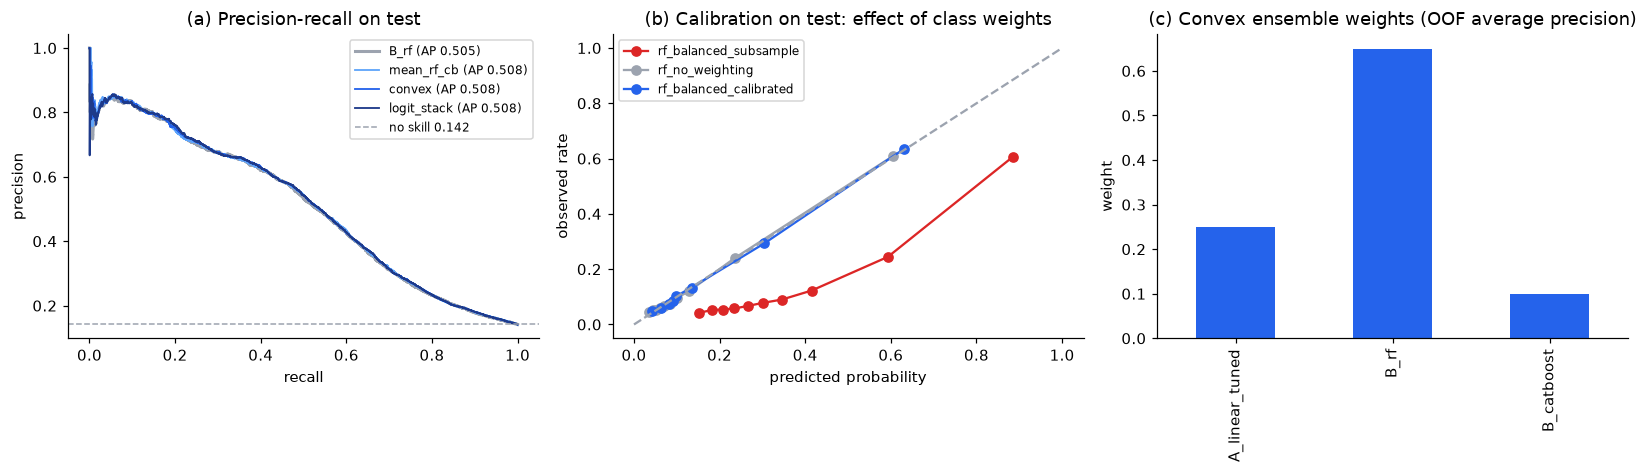

In [32]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4.4))
show = [best_single, "mean_rf_cb", "convex", "logit_stack"]
pal = dict(zip(show, [GREY, "#60a5fa", ACCENT, "#1e3a8a"]))
for n in show:
    pr, rc, _ = precision_recall_curve(y_te, test_proba[n])
    ax[0].plot(rc, pr, color=pal[n], lw=2 if n == FINAL else 1.2, label=f"{n} (AP {test_tbl.loc[n,'pr_auc']:.3f})")
ax[0].axhline(y_te.mean(), ls="--", color=GREY, lw=1, label=f"no skill {y_te.mean():.3f}")
ax[0].set_xlabel("recall"); ax[0].set_ylabel("precision"); ax[0].set_title("(a) Precision-recall on test"); ax[0].legend(fontsize=8)
for n, c in (("rf_balanced_subsample", RED), ("rf_no_weighting", GREY), ("rf_balanced_calibrated", ACCENT)):
    if n in probs:
        f, m = calibration_curve(y_te, probs[n][1], n_bins=10, strategy="quantile"); ax[1].plot(m, f, marker="o", color=c, label=n)
ax[1].plot([0, 1], [0, 1], ls="--", color=GREY); ax[1].set_xlabel("predicted probability"); ax[1].set_ylabel("observed rate")
ax[1].set_title("(b) Calibration on test: effect of class weights"); ax[1].legend(fontsize=8)
weights.convex_weight.plot.bar(ax=ax[2], color=ACCENT); ax[2].set_title("(c) Convex ensemble weights (OOF average precision)"); ax[2].set_ylabel("weight")
plt.tight_layout(); fig.savefig(OUT / "figures/04_ensemble_comparison.png", bbox_inches="tight")

## C9. Save

In [33]:
config.MODELS_DIR.mkdir(parents=True, exist_ok=True)
summary = {"final": FINAL, "ensemble_retained": bool(keep), "best_single": best_single, "best_ensemble": best_ens,
           "thresholds": thresholds, "convex_weights": dict(zip(oof.columns, map(float, w_convex))),
           "oof_rows": int(len(oof)), "quick_mode": QUICK, "val_pr_auc": val_tbl.pr_auc.round(4).to_dict(),
           "test_pr_auc": test_tbl.pr_auc.round(4).to_dict()}
json.dump(summary, open(OUT / "ensemble_summary.json", "w"), indent=2, default=str)
(OUT / "oof").mkdir(exist_ok=True)
oof.assign(is_low_review=y_oof.values, order_id=S["train"].order_id.iloc[oof.index].values).to_csv(OUT / "oof/base_oof_probabilities.csv", index=False)
joblib.dump({"base": fitted, "method": FINAL, "convex_weights": w_convex, "meta": meta, "threshold": thresholds[FINAL],
             "features": list(X_tr.columns), "problem": PROBLEM}, config.MODELS_DIR / "ensemble_bundle.joblib")
print(json.dumps({k: summary[k] for k in ("final", "ensemble_retained", "best_single", "best_ensemble", "oof_rows")}, indent=2))

{
  "final": "B_rf",
  "ensemble_retained": false,
  "best_single": "B_rf",
  "best_ensemble": "logit_stack",
  "oof_rows": 52254
}


## C10. Areas that need attention

Read these against the tables above before quoting any number in the report.

1. **The split is stratified and random in time** (Zaghloul et al. 2024 design, brief's "stratified splits for
   imbalanced targets"). Validation and test therefore share the training rows' month mix and positive rate, so
   their scores estimate performance on the 2016-18 order mix, not on a future month; March 2018 (postal strike)
   is diluted into every partition. The chronological robustness check in `docs/current_progress.md` reports the
   same final configuration on the July-August 2018 hold-out so the drift cost is visible. Say both in the report.
2. **Training features never see validation / test labels.** Seller and route history aggregate outcomes of
   training rows only (audit row "late rate rebuilt from training-row outcomes only" = 1.0). This is stricter
   than production, where all past outcomes would be available, so history features are slightly weaker here.
3. **Class weights distort probabilities, not rankings.** The balance study shows near-identical PR-AUC across
   weighting choices but very different Brier scores and flag rates at 0.5. If the risk score is shown to the CX
   team as a probability, use the calibrated variant; if it is only used to rank, weighting is harmless.
4. **The ensemble gain is small by construction.** The three base models rank the same orders similarly (see
   the OOF correlation matrix), so averaging mostly reduces variance. Keep the retention rule honest: if the
   best ensemble is not at least 1% better on validation, the report says so and keeps the single model.
5. **Survey-trigger reconstruction.** T = min(delivered, estimated) is derived, not logged. No cohort order was
   *answered* before T (the 426 that were are excluded); 2.7% of surveys were *created* before T, which bounds the
   error of the reconstruction and belongs in Limitations as such — not as reviews written before T.
6. **Validation and test can still disagree on the ensemble** because the retention rule uses one 13% slice.
   The OOF rows (all training rows) are a larger selection set; if the team prefers "better on OOF *and* not
   worse on validation", decide that before reading the full-run test numbers and record it in
   docs/ensemble_comparison.md.
7. **Run `baseline_variant_review` in full before this notebook.** Base configurations are read from
   `outputs/selected_models.json`; the defaults here are placeholders, and a QUICK run writes QUICK parameters
   into that file.

# Part D — Sampling comparison and SHAP — low-review classification

Zaghloul et al. (2024) retrain every classifier under `RandomOverSampler`, `SMOTE` and `ADASYN` (their Experiment 4)
and report accuracy, weighted precision / recall / F1 and AUC-ROC. This notebook repeats that study on our protocol,
adds the two strategies the brief names (no adjustment, class weights) and the imbalance-aware metrics the brief asks
for (PR-AUC, balanced accuracy, Brier), then explains the final model with SHAP.

* **Grid**: 4 models (tuned logistic, decision tree, random forest, CatBoost; configurations from
  `outputs/selected_models.json`) × 5 strategies (`none`, `class_weight`, `random_oversampler`, `smote`, `adasyn`) = 20 fits.
  No re-tuning: the question is what the imbalance strategy does to a fixed model.
* Resampling runs **inside** an imbalanced-learn pipeline after the preprocessor, on training rows only.
  CatBoost uses the forest's numeric matrix here (SMOTE / ADASYN cannot interpolate string categories); its native
  categorical result is the ladder row in `model_comparison.csv`.
* Thresholds are chosen on validation (F1) and frozen; the test set is scored once per cell. The strategy marked
  `*` per model is chosen on **validation** PR-AUC; test columns are reported for every cell for completeness and
  are never used to choose anything.
* **SHAP**: TreeExplainer on the final forest (and CatBoost as a cross-check), with one-hot and indicator columns
  folded back onto the original features; the exact linear SHAP of the logistic model as a sanity check.

Set `QUICK = True` for a dry run (small forests / CatBoost); the report numbers come from `QUICK = False`.

*Compiled from `sampling_comparison.ipynb`.*

### Part D setup

In [34]:
import joblib, json, time
from sklearn.base import clone
import clf_sampling as sampling, clf_explain as explain

QUICK = False
PROBLEM = "p2"
OUT = config.ROOT / "outputs"
best = json.load(open(OUT / "selected_models.json"))
print("configurations from baseline_variant_review | final model:", best["final_model"], "| quick:", best["quick_mode"])


configurations from baseline_variant_review | final model: B_rf | quick: False


## D1. Data

In [35]:
df = features.load_feature_table()
cohort = features.cohort(df, PROBLEM)
S = split.split_frame(cohort)
X_tr, y_tr = split.xy(S["train"], PROBLEM); X_va, y_va = split.xy(S["validation"], PROBLEM); X_te, y_te = split.xy(S["test"], PROBLEM)
print({k: v.shape for k, v in S.items()}, "| positive rate", round(y_tr.mean(), 4))

{'train': (52254, 78), 'validation': (13064, 78), 'test': (32172, 78)} | positive rate 0.1415


## D2. The 20 fits

Tuned parameters are taken from the ladder; the CatBoost iteration count is the early-stopped one when it was retained.
`fit_seconds` and `train_rows_after_sampling` are recorded because the paper's main finding about resampling is cost.

In [36]:
params = {m: dict(best["best_params"].get(m, {})) for m in sampling.MODELS}
if QUICK:
    params["B_rf"]["model__n_estimators"] = 100; params["B_catboost"]["model__iterations"] = 150
rows, fitted, proba = [], {}, {}
for model in sampling.MODELS:
    for strategy in sampling.STRATEGIES:
        t0 = time.time()
        pipe = sampling.build(model, strategy, PROBLEM, params[model]).fit(X_tr, y_tr)
        p_va, p_te = pipe.predict_proba(X_va)[:, 1], pipe.predict_proba(X_te)[:, 1]
        thr = evaluate.best_threshold(y_va, p_va)
        mv, mt = evaluate.classification_metrics(y_va, p_va, thr), evaluate.classification_metrics(y_te, p_te, thr)
        n_after = len(y_tr)
        if strategy not in ("none", "class_weight"):
            n_after = len(pipe.named_steps["sample"].fit_resample(pipe[:2].transform(X_tr), y_tr)[1])   # history -> pre
        rows.append({"model": model, "strategy": strategy, "fit_seconds": round(time.time() - t0, 1),
                     "train_rows_after_sampling": n_after, "threshold": thr,
                     **{f"val_{k}": v for k, v in mv.items() if k != "threshold"},
                     **{f"test_{k}": v for k, v in mt.items() if k != "threshold"}})
        fitted[(model, strategy)], proba[(model, strategy)] = pipe, (p_va, p_te)
        print(f"{model:15s} {strategy:19s} val PR-AUC {mv['pr_auc']:.3f}  test PR-AUC {mt['pr_auc']:.3f}  "
              f"ROC {mt['roc_auc']:.3f}  Brier {mt['brier']:.3f}  rows {n_after:6d}  {time.time()-t0:.0f}s")
res = pd.DataFrame(rows).set_index(["model", "strategy"])
res.to_csv(OUT / "tables/sampling_comparison.csv")

A_linear_tuned  none                val PR-AUC 0.471  test PR-AUC 0.493  ROC 0.784  Brier 0.093  rows  52254  4s
A_linear_tuned  class_weight        val PR-AUC 0.469  test PR-AUC 0.490  ROC 0.786  Brier 0.166  rows  52254  3s
A_linear_tuned  random_oversampler  val PR-AUC 0.468  test PR-AUC 0.490  ROC 0.786  Brier 0.166  rows  89720  7s
A_linear_tuned  smote               val PR-AUC 0.465  test PR-AUC 0.489  ROC 0.783  Brier 0.166  rows  89720  6s
A_linear_tuned  adasyn              val PR-AUC 0.457  test PR-AUC 0.480  ROC 0.782  Brier 0.198  rows  90716  15s
B_tree_base     none                val PR-AUC 0.469  test PR-AUC 0.476  ROC 0.771  Brier 0.094  rows  52254  7s
B_tree_base     class_weight        val PR-AUC 0.469  test PR-AUC 0.484  ROC 0.771  Brier 0.167  rows  52254  7s
B_tree_base     random_oversampler  val PR-AUC 0.452  test PR-AUC 0.476  ROC 0.770  Brier 0.164  rows  89720  12s
B_tree_base     smote               val PR-AUC 0.444  test PR-AUC 0.470  ROC 0.759  Brier 0.10

## D3. Results

Two views of the same table: (a) the imbalance-aware metrics the brief asks for, (b) the paper's metrics
(accuracy and class-size-weighted precision / recall / F1), which are dominated by the 86% majority class and
therefore barely move between strategies. The best strategy per model by **validation** PR-AUC is marked.

In [37]:
cols_a = ["val_pr_auc", "test_pr_auc", "test_roc_auc", "test_balanced_acc", "test_brier", "test_precision", "test_recall", "test_f1", "test_flag_rate", "threshold", "fit_seconds"]
tab_a = res[cols_a].round(3)
best_by_model = res.groupby(level=0).val_pr_auc.idxmax()
tab_a["best_on_validation"] = ["*" if idx in set(best_by_model) else "" for idx in res.index]
display(tab_a)
cols_b = ["test_accuracy", "test_precision_weighted", "test_recall_weighted", "test_f1_weighted", "test_roc_auc", "train_rows_after_sampling"]
res[cols_b].round(3)

val_pr_auc  test_pr_auc  test_roc_auc  test_balanced_acc  test_brier  test_precision  test_recall  test_f1  test_flag_rate  \
model          strategy                                                                                                                                         
A_linear_tuned none                     0.471        0.493         0.784              0.712       0.093           0.546        0.491    0.517           0.127   
               class_weight             0.469        0.490         0.786              0.713       0.166           0.545        0.494    0.518           0.128   
               random_oversampler       0.468        0.490         0.786              0.714       0.166           0.542        0.497    0.519           0.130   
               smote                    0.465        0.489         0.783              0.718       0.166           0.518        0.516    0.517           0.141   
               adasyn                   0.457        0.480         0.782              0.719       0.198           0.511        0.520    0.515           0.144   
B_tree_base    none                     0.469        0.476         0.771              0.712       0.094           0.547        0.492    0.518           0.127   
               class_weight             0.469        0.484         0.771              0.723       0.167           0.468        0.549    0.505           0.166   
               random_oversampler       0.452        0.476         0.770              0.707       0.164           0.522        0.486    0.504           0.132   
               smote                    0.444        0.470         0.759              0.711       0.103           0.506        0.503    0.505           0.141   
               adasyn                   0.445        0.463         0.758              0.703       0.103           0.535        0.474    0.503           0.126   
B_rf           none                     0.491        0.506         0.788              0.715       0.092           0.537        0.502    0.519           0.132   
               class_weight             0.491        0.505         0.788              0.720       0.145           0.508        0.523    0.515           0.146   
               random_oversampler       0.489        0.505         0.787              0.714       0.146           0.542        0.498    0.519           0.130   
               smote                    0.477        0.498         0.782              0.706       0.099           0.555        0.476    0.512           0.121   
               adasyn                   0.477        0.496         0.781              0.710       0.099           0.545        0.488    0.515           0.127   
B_catboost     none                     0.487        0.509         0.789              0.716       0.092           0.536        0.505    0.520           0.133   
               class_weight             0.485        0.502         0.788              0.708       0.160           0.559        0.479    0.516           0.121   
               random_oversampler       0.484        0.501         0.789              0.714       0.157           0.538        0.499    0.518           0.131   
               smote                    0.480        0.505         0.786              0.716       0.093           0.530        0.506    0.517           0.135   
               adasyn                   0.481        0.505         0.786              0.718       0.093           0.522        0.514    0.518           0.139   

                                   threshold  fit_seconds best_on_validation  
model          strategy                                                       
A_linear_tuned none                    0.248          4.1                  *  
               class_weight            0.684          3.0                     
               random_oversampler      0.675          6.8                     
               smote                   0.622          6.0                     
               ada

test_accuracy  test_precision_weighted  test_recall_weighted  test_f1_weighted  test_roc_auc  train_rows_after_sampling
model          strategy                                                                                                                                   
A_linear_tuned none                        0.870                    0.865                 0.870             0.867         0.784                      52254
               class_weight                0.870                    0.865                 0.870             0.867         0.786                      52254
               random_oversampler          0.869                    0.865                 0.869             0.867         0.786                      89720
               smote                       0.864                    0.863                 0.864             0.863         0.783                      89720
               adasyn                      0.862                    0.863                 0.862             0.862         0.782                      90716
B_tree_base    none                        0.870                    0.865                 0.870             0.868         0.771                      52254
               class_weight                0.848                    0.859                 0.848             0.853         0.771                      52254
               random_oversampler          0.864                    0.860                 0.864             0.862         0.770                      89720
               smote                       0.860                    0.860                 0.860             0.860         0.759                      89720
               adasyn                      0.867                    0.861                 0.867             0.864         0.758                      90015
B_rf           none                        0.868                    0.865                 0.868             0.866         0.788                      52254
               class_weight                0.861                    0.863                 0.861             0.862         0.788                      52254
               random_oversampler          0.869                    0.865                 0.869             0.867         0.787                      89720
               smote                       0.872                    0.865                 0.872             0.868         0.782                      89720
               adasyn                      0.870                    0.864                 0.870             0.867         0.781                      90015
B_catboost     none                        0.868                    0.865                 0.868             0.866         0.789                      52254
               class_weight                0.873                    0.866                 0.873             0.869         0.788                      52254
               random_oversampler          0.869                    0.865                 0.869             0.866         0.789                      89720
               smote                       0.867                    0.864                 0.867             0.865         0.786                      89720
               adasyn                      0.865                    0.864                 0.865             0.864         0.786                      90015

In [38]:
# strategy effect relative to 'none', per model (test PR-AUC and Brier)
delta = res.test_pr_auc.unstack("strategy")[sampling.STRATEGIES]
delta_brier = res.test_brier.unstack("strategy")[sampling.STRATEGIES]
print("test PR-AUC by strategy"); display(delta.round(3))
print("test Brier by strategy (lower is better)"); display(delta_brier.round(3))

test PR-AUC by strategy


strategy,none,class_weight,random_oversampler,smote,adasyn
model,,,,,
A_linear_tuned,0.493,0.490,0.490,0.489,0.480
B_catboost,0.509,0.502,0.501,0.505,0.505
B_rf,0.506,0.505,0.505,0.498,0.496
B_tree_base,0.476,0.484,0.476,0.470,0.463


test Brier by strategy (lower is better)


strategy,none,class_weight,random_oversampler,smote,adasyn
model,,,,,
A_linear_tuned,0.093,0.166,0.166,0.166,0.198
B_catboost,0.092,0.160,0.157,0.093,0.093
B_rf,0.092,0.145,0.146,0.099,0.099
B_tree_base,0.094,0.167,0.164,0.103,0.103


## D4. Figure (report Figure 5)

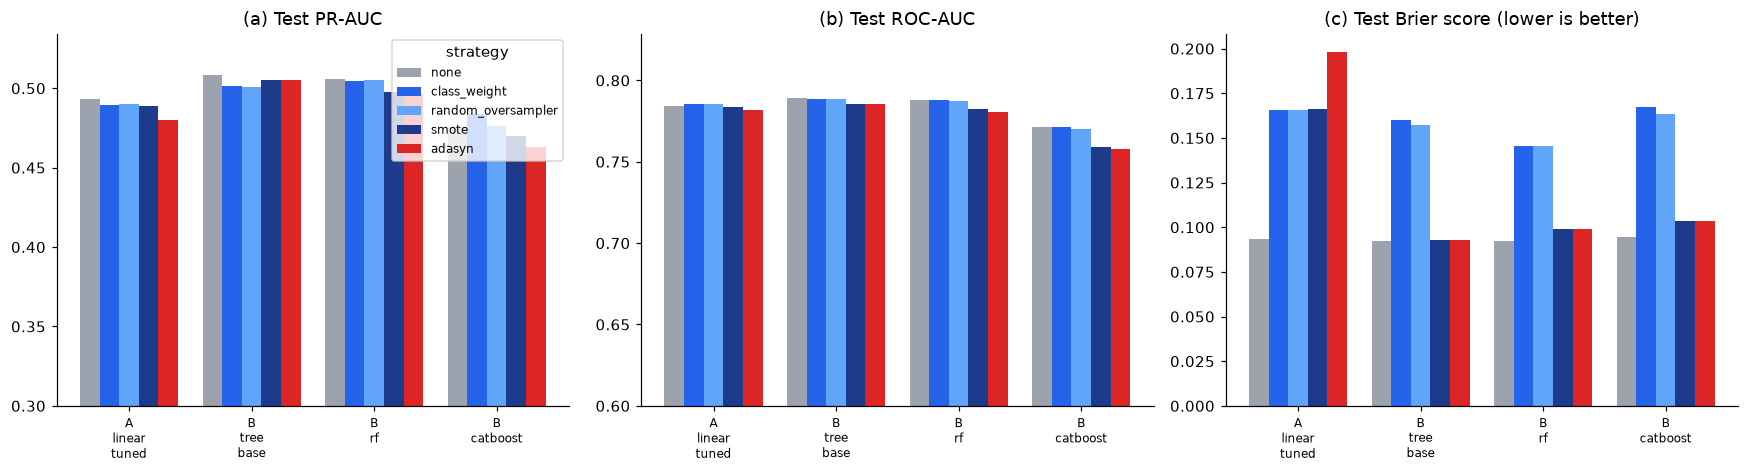

In [39]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.4))
pal = dict(zip(sampling.STRATEGIES, [GREY, ACCENT, "#60a5fa", "#1e3a8a", RED]))
w = 0.16; x = np.arange(len(sampling.MODELS))
for j, strat in enumerate(sampling.STRATEGIES):
    ax[0].bar(x + (j - 2) * w, delta[strat].values, w, color=pal[strat], label=strat)
    ax[1].bar(x + (j - 2) * w, res.test_roc_auc.unstack("strategy")[strat].values, w, color=pal[strat])
    ax[2].bar(x + (j - 2) * w, delta_brier[strat].values, w, color=pal[strat])
for a, t in zip(ax, ("(a) Test PR-AUC", "(b) Test ROC-AUC", "(c) Test Brier score (lower is better)")):
    a.set_xticks(x); a.set_xticklabels([m.replace("_", "\n") for m in sampling.MODELS], fontsize=8); a.set_title(t)
ax[0].axhline(y_te.mean(), ls="--", color=GREY, lw=1); ax[0].set_ylim(0.3, None); ax[1].set_ylim(0.6, None)
ax[0].legend(fontsize=8, title="strategy")
plt.tight_layout(); fig.savefig(OUT / "figures/05_sampling_comparison.png", bbox_inches="tight")

## D5. SHAP on the final model

`shap.TreeExplainer` on the forest under its retained strategy (positive-class contributions, 1,500 validation rows).
One-hot and missing-indicator columns are summed back onto their original feature for the bar chart so it is
comparable with the permutation importance in `baseline_variant_review`. The beeswarm keeps the transformer columns
so the direction of each effect is visible.

In [40]:
import shap
FINAL = best["final_model"] if best["final_model"] in sampling.MODELS else "B_rf"
FINAL_STRATEGY = best_by_model[FINAL][1]
pipe = fitted[(FINAL, FINAL_STRATEGY)]
print("explaining", FINAL, "under", FINAL_STRATEGY)
t0 = time.time()
sv, M, names, base_value, idx = explain.shap_tree(pipe, X_va, max_rows=600 if QUICK else 1500)
print(f"SHAP values {sv.shape} in {time.time()-t0:.0f}s; base value {base_value:.3f}")
grouped = explain.group_by_feature(sv, names, config.features_for(PROBLEM))
grouped.to_csv(OUT / "tables/shap_importance.csv", index=False)
grouped.head(15)

explaining B_rf under none
SHAP values (1500, 121) in 226s; base value 0.141


,feature,mean_abs_shap,columns
0,n_items,0.018528,1
1,actual_delivery_time,0.013995,2
2,wd_actual_delivery_time,0.013748,2
3,wd_delivery_time_delta,0.013493,2
4,carrier_transit_days,0.013229,2
5,is_delivered,0.012931,1
6,delivery_time_delta,0.012231,2
7,delivery_vs_seller_prior,0.012010,2
8,seller_id_enc,0.010241,1
9,carrier_handover_days,0.005862,2


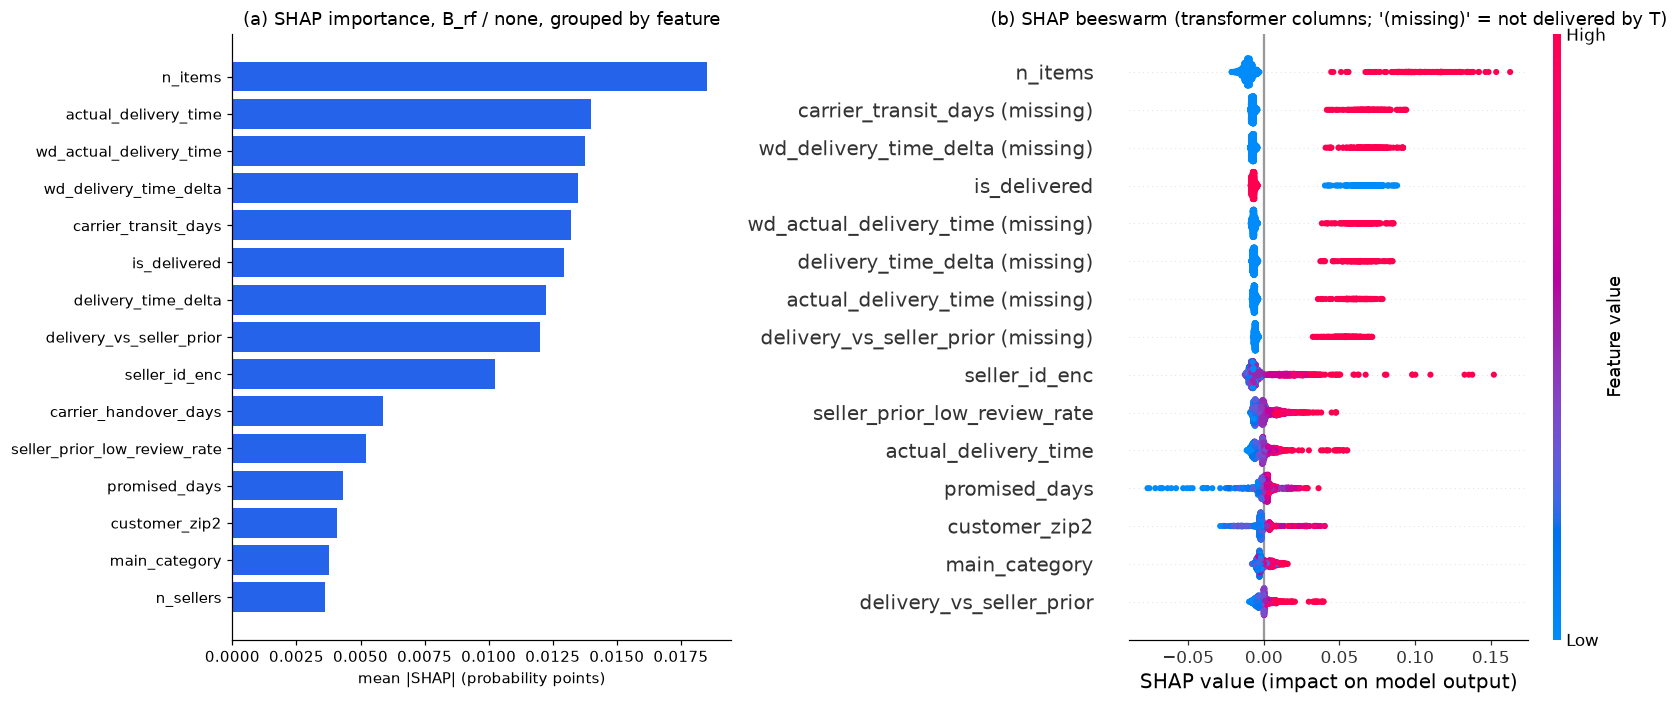

In [41]:
fig, ax = plt.subplots(1, 2, figsize=(15, 6.5))
top = grouped.head(15)
ax[0].barh(top.feature[::-1], top.mean_abs_shap[::-1], color=ACCENT)
ax[0].set_xlabel("mean |SHAP| (probability points)"); ax[0].set_title(f"(a) SHAP importance, {FINAL} / {FINAL_STRATEGY}, grouped by feature")
plt.sca(ax[1])
short = [explain.original_feature(n, config.features_for(PROBLEM), keep_indicators=True) if n.startswith(("num__", "skew__", "high__")) else n.split("__", 1)[-1] for n in names]
shap.summary_plot(sv, M, feature_names=short, max_display=15, show=False, plot_size=None)
ax[1].set_title("(b) SHAP beeswarm (transformer columns; '(missing)' = not delivered by T)")
plt.tight_layout(); fig.savefig(OUT / "figures/06_shap_summary.png", bbox_inches="tight")

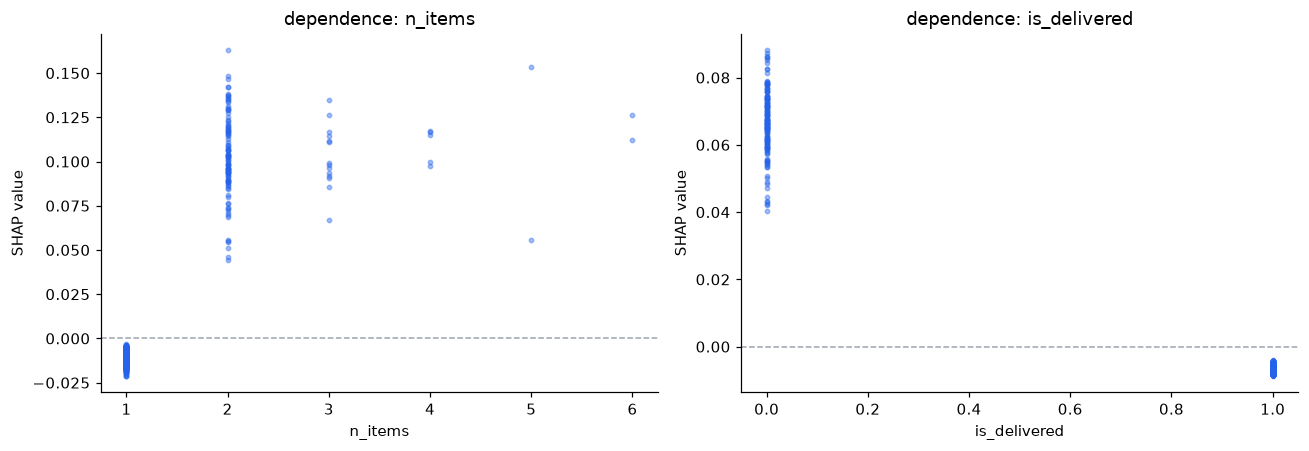

In [42]:
# dependence of the two strongest numeric effects
num_cols = [n for n in names if n.startswith("num__") and "missingindicator" not in n]
top_num = sorted(num_cols, key=lambda n: -np.abs(sv[:, names.index(n)]).mean())[:2]
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
for a, n in zip(ax, top_num):
    j = names.index(n); ok = ~np.isnan(M[:, j])
    a.scatter(M[ok, j], sv[ok, j], s=8, alpha=0.4, color=ACCENT)
    a.axhline(0, ls="--", color=GREY, lw=1); a.set_xlabel(n.split("__", 1)[1]); a.set_ylabel("SHAP value")
    a.set_title(f"dependence: {n.split('__', 1)[1]}")
plt.tight_layout(); fig.savefig(OUT / "figures/07_shap_dependence.png", bbox_inches="tight")

### Cross-checks: CatBoost SHAP and exact linear SHAP

If the three model families agree on the top features, the ranking is a property of the data rather than of one
algorithm. Units differ (the forest explains probabilities, CatBoost and the logistic model explain log-odds), so
only the **ranks** are compared: Spearman correlation of the grouped mean |SHAP| is printed.

In [43]:
cb_sv, cb_M, cb_names, _, _ = explain.shap_tree(fitted[("B_catboost", best_by_model["B_catboost"][1])], X_va, max_rows=600 if QUICK else 1500)
cb_grouped = explain.group_by_feature(cb_sv, cb_names, config.features_for(PROBLEM))
lin_sv, lin_M, lin_names, _, _ = explain.shap_linear(fitted[("A_linear_tuned", best_by_model["A_linear_tuned"][1])], X_va, max_rows=600 if QUICK else 1500)
lin_grouped = explain.group_by_feature(lin_sv, lin_names, config.features_for(PROBLEM))
cmp = (grouped.set_index("feature").mean_abs_shap.rename("rf")
       .to_frame().join(cb_grouped.set_index("feature").mean_abs_shap.rename("catboost"))
       .join(lin_grouped.set_index("feature").mean_abs_shap.rename("logistic")))
cmp = cmp.fillna(0).sort_values("rf", ascending=False)
cmp.to_csv(OUT / "tables/shap_cross_model.csv")
print("Spearman rank correlation of grouped mean |SHAP|:"); display(cmp.rank().corr(method="spearman").round(2))
cmp.head(12).round(4)

Spearman rank correlation of grouped mean |SHAP|:


,rf,catboost,logistic
rf,1.00,0.92,0.44
catboost,0.92,1.00,0.49
logistic,0.44,0.49,1.00


,rf,catboost,logistic
feature,,,
n_items,0.0185,0.1615,0.0834
actual_delivery_time,0.0140,0.1259,0.0707
wd_actual_delivery_time,0.0137,0.0828,0.0937
wd_delivery_time_delta,0.0135,0.0540,0.1074
carrier_transit_days,0.0132,0.0520,0.1980
is_delivered,0.0129,0.0853,0.0709
delivery_time_delta,0.0122,0.0483,0.2660
delivery_vs_seller_prior,0.0120,0.0834,0.0869
seller_id_enc,0.0102,0.1107,0.0382


## D6. Save

In [44]:
summary = {"strategies": sampling.STRATEGIES, "models": sampling.MODELS,
           "best_strategy_by_model_on_validation": {m: s for m, s in best_by_model.values},
           "final_model": FINAL, "final_strategy": FINAL_STRATEGY, "quick_mode": QUICK,
           "test_pr_auc": {f"{m}/{s}": round(v, 4) for (m, s), v in res.test_pr_auc.items()},
           "shap_top10": grouped.head(10).feature.tolist()}
json.dump(summary, open(OUT / "sampling_summary.json", "w"), indent=2)
joblib.dump({"pipeline": pipe, "model": FINAL, "strategy": FINAL_STRATEGY, "threshold": float(res.loc[(FINAL, FINAL_STRATEGY), "threshold"])},
            config.MODELS_DIR / "sampling_final.joblib")
print(json.dumps({k: summary[k] for k in ("best_strategy_by_model_on_validation", "final_model", "final_strategy", "shap_top10")}, indent=2))

{
  "best_strategy_by_model_on_validation": {
    "A_linear_tuned": "none",
    "B_catboost": "none",
    "B_rf": "none",
    "B_tree_base": "class_weight"
  },
  "final_model": "B_rf",
  "final_strategy": "none",
  "shap_top10": [
    "n_items",
    "actual_delivery_time",
    "wd_actual_delivery_time",
    "wd_delivery_time_delta",
    "carrier_transit_days",
    "is_delivered",
    "delivery_time_delta",
    "delivery_vs_seller_prior",
    "seller_id_enc",
    "carrier_handover_days"
  ]
}


## D7. Reading the results

* **Ranking vs scale.** Compare the PR-AUC and ROC-AUC rows across strategies with the Brier rows: on this target the
  strategies move the probability scale (Brier, flag rate at the default cut) far more than the ranking. The paper's
  accuracy / weighted-F1 gains after oversampling are small for the same reason.
* **Cost.** `train_rows_after_sampling` roughly doubles under oversampling, and `fit_seconds` with it; ADASYN adds the
  most synthetic rows in the hardest regions.
* **Which to retain.** The report should keep the ladder's class-weight choice unless a resampler wins on validation
  PR-AUC by the same ≥ 1% relative rule used elsewhere, and should say so in Section 6.3.
* **SHAP vs permutation importance.** Both are on the validation set; if the top-5 lists agree the interpretation
  section can quote either. Grouped SHAP sums a feature's one-hot and missing-indicator columns per row before taking
  the mean absolute value, so high-cardinality categoricals are not penalised for being spread across columns and the
  "not delivered by T" effect is attributed to the delivery-as-of-T features it belongs to rather than appearing once
  per indicator.